In [1]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import numpy as np
import scienceplots

from pybaselines import Baseline, utils

from scipy.optimize import curve_fit
from scipy.signal import savgol_filter
from scipy.ndimage import binary_dilation
from scipy.signal import find_peaks
from scipy.stats import chisquare

from astropy.stats import median_absolute_deviation as MAD
from astropy.modeling import models, fitting
from astropy.convolution import convolve_models

from MPG_HDF5_libs import *

In [2]:
# configuration for the plots
plt.style.use(['science', 'no-latex'])

plt.rcParams.update({
    "axes.labelsize": 14,  # Font size for axis labels
    "xtick.labelsize": 14,  # Font size for x-axis tick labels
    "ytick.labelsize": 14   # Font size for y-axis tick labels
})   

In [3]:
filename = ('/home/chavango/Master/DATA/SKAMPI_data/EDD_2023-03-11T14_58_01.567317UTC_ErQFG.hdf5')
f = h5py.File(filename, 'r')

In [4]:
list(f.keys())

['history', 'monitor', 'scan']

In [5]:
group_1 = f['monitor']
group_1.keys()

<KeysViewHDF5 ['acu', 'rxs', 'weather']>

In [6]:
# Let's porint the structure of the hdf5 file

def print_hdf5_structure(name, obj):
    indent = '  ' * name.count('/')
    if isinstance(obj, h5py.Group):
        print(f"{indent}Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"{indent}Dataset: {name}, Shape: {obj.shape}, Dtype: {obj.dtype}")


f.visititems(print_hdf5_structure)

Dataset: history, Shape: (9,), Dtype: [('processingtime', 'S23'), ('software', 'S256'), ('version', 'S128'), ('comment', 'S256')]
Group: monitor
  Group: monitor/acu
    Dataset: monitor/acu/actual_timestamp, Shape: (2650,), Dtype: float64
    Group: monitor/acu/ambient_temp_correction_config
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_1, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_10, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_2, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_3, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_4, Shape: (2650,), Dtype: float64
      Dataset: monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_5a, Shape: (2650,), Dtype: float64
      Dataset:

In [7]:
time=f['scan/000/P1_ND1/timestamp']
time[0][0]

np.float64(1678546719.08443)

In [8]:
time_obs = time
time_obs= np.squeeze(time_obs)
time_obs[:10]

array([1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09])

In [9]:

# Example Unix timestamp
unix_time = time_obs

# Convert to numpy datetime64 directly (faster!)
utc_times = np.array(time_obs, dtype="datetime64[s]")

print(f"UTC Time: {utc_times} \n Data_shape: {utc_times.shape}")

UTC Time: ['2023-03-11T14:58:39' '2023-03-11T14:58:39' '2023-03-11T14:58:39'
 '2023-03-11T14:58:39' '2023-03-11T14:58:39' '2023-03-11T14:58:39'
 '2023-03-11T14:58:40' '2023-03-11T14:58:40' '2023-03-11T14:58:40'
 '2023-03-11T14:58:40' '2023-03-11T14:58:40' '2023-03-11T14:58:40'
 '2023-03-11T14:58:40' '2023-03-11T14:58:41' '2023-03-11T14:58:41'
 '2023-03-11T14:58:41' '2023-03-11T14:58:41' '2023-03-11T14:58:41'
 '2023-03-11T14:58:41' '2023-03-11T14:58:41' '2023-03-11T14:58:42'
 '2023-03-11T14:58:42' '2023-03-11T14:58:42' '2023-03-11T14:58:42'
 '2023-03-11T14:58:42' '2023-03-11T14:58:42' '2023-03-11T14:58:43'
 '2023-03-11T14:58:43' '2023-03-11T14:58:43' '2023-03-11T14:58:43'
 '2023-03-11T14:58:43' '2023-03-11T14:58:43' '2023-03-11T14:58:43'
 '2023-03-11T14:58:44' '2023-03-11T14:58:44' '2023-03-11T14:58:44'
 '2023-03-11T14:58:44' '2023-03-11T14:58:44' '2023-03-11T14:58:44'
 '2023-03-11T14:58:45' '2023-03-11T14:58:45' '2023-03-11T14:58:45'
 '2023-03-11T14:58:45' '2023-03-11T14:58:45' '2023-0

In [10]:
# formatted = [dt.strftime("%Y-%m-%d %H:%M:%S UTC") for dt in utc_times]
# print("Formatted:", formatted)

In [11]:
# read attribute of dataset
dataset = f['monitor/acu/ambient_temp_correction_config/ambient_factor_az_band_9']
dataset[:]

array([3.9742646, 3.9742646, 3.9742646, ..., 3.9742646, 3.9742646,
       3.9742646], shape=(2650,))

In [12]:
find_key = ['timestamp']

print('\n\t=== extract ',find_key,' ===\n')

data_key = findkeys(f,keys=find_key,exactmatch=True)

for d in data_key:
    print('\tkey  : ',d)
    print('\tshape: ',f[d].shape)
    #print('\tfirst data entry: ',obsfile[d][:],'\n')
print('\t++++++++++++++++++++++++++++\n')



# get the data keys of the timestamping in the scans and spectra
#
timestamp_keys       = findkeys(f,keys=['scan','timestamp'],exactmatch=True)
#
spectrum_keys        = findkeys(f,keys=['scan','spectrum'],exactmatch=True)
# #########  
#



	=== extract  ['timestamp']  ===

	key  :  monitor/weather/timestamp
	shape:  (32,)
	key  :  scan/000/P0_ND0/timestamp
	shape:  (664, 1)
	key  :  scan/000/P0_ND1/timestamp
	shape:  (664, 1)
	key  :  scan/000/P1_ND0/timestamp
	shape:  (664, 1)
	key  :  scan/000/P1_ND1/timestamp
	shape:  (664, 1)
	key  :  scan/001/P0_ND0/timestamp
	shape:  (666, 1)
	key  :  scan/001/P0_ND1/timestamp
	shape:  (666, 1)
	key  :  scan/001/P1_ND0/timestamp
	shape:  (666, 1)
	key  :  scan/001/P1_ND1/timestamp
	shape:  (666, 1)
	++++++++++++++++++++++++++++



In [13]:
with h5py.File(filename, "r") as f:
    def print_structure(name, obj):
        print(name, obj.shape if hasattr(obj, "shape") else "group")
    f['scan'].visititems(print_structure)

000 group
000/P0_ND0 group
000/P0_ND0/azimuth (664,)
000/P0_ND0/dec (664,)
000/P0_ND0/elevation (664,)
000/P0_ND0/frequency (65537,)
000/P0_ND0/integration_time (664, 1)
000/P0_ND0/mask (664, 65537)
000/P0_ND0/power (664,)
000/P0_ND0/ra (664,)
000/P0_ND0/saturated_samples (664, 1)
000/P0_ND0/spectrum (664, 65537)
000/P0_ND0/timestamp (664, 1)
000/P0_ND1 group
000/P0_ND1/azimuth (664,)
000/P0_ND1/dec (664,)
000/P0_ND1/elevation (664,)
000/P0_ND1/integration_time (664, 1)
000/P0_ND1/mask (664, 65537)
000/P0_ND1/power (664,)
000/P0_ND1/ra (664,)
000/P0_ND1/saturated_samples (664, 1)
000/P0_ND1/spectrum (664, 65537)
000/P0_ND1/timestamp (664, 1)
000/P1_ND0 group
000/P1_ND0/azimuth (664,)
000/P1_ND0/dec (664,)
000/P1_ND0/elevation (664,)
000/P1_ND0/integration_time (664, 1)
000/P1_ND0/mask (664, 65537)
000/P1_ND0/power (664,)
000/P1_ND0/ra (664,)
000/P1_ND0/saturated_samples (664, 1)
000/P1_ND0/spectrum (664, 65537)
000/P1_ND0/timestamp (664, 1)
000/P1_ND1 group
000/P1_ND1/azimuth (664,)
00

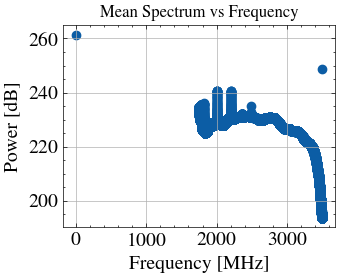

In [14]:
with h5py.File(filename, "r") as f:
    scan = f['scan/000/P1_ND0'] # select one scan

    # define the variables
    spectrum = scan['spectrum'][:] # shape (666, 65537)
    freq = scan['frequency'][:] /1e6  # convert Hz -> MHz shape (65537,)
    time = scan['timestamp'][:,0]  # shape  (666,)  

# Plot the mean spectrum vs frequency
mean_spect = np.nanmean(10*np.log10(spectrum**2), axis=0) # in dB

plt.scatter(freq, mean_spect)
plt.xlabel('Frequency [MHz]')
plt.ylabel('Power [dB]')
plt.title('Mean Spectrum vs Frequency')
plt.grid()
plt.show()


In [15]:
spectrum.shape

(664, 65537)

The two outlier must be flagged out, and to that we need to set the frequency range from 1600:-1. <br>
The -1 is to take out the the last value.


As the spectrum bidimensional (ntime, nfreq), if we need a certain range for time or frequency we need to do so at <br>
expecific space. For instance, we need to set a range for the frequency then we will do it at the frequency domain on <br>
the Spectrum, i.e, spectrum=['scan/000/P1_NDO/spectrum'][:,1600:-1].

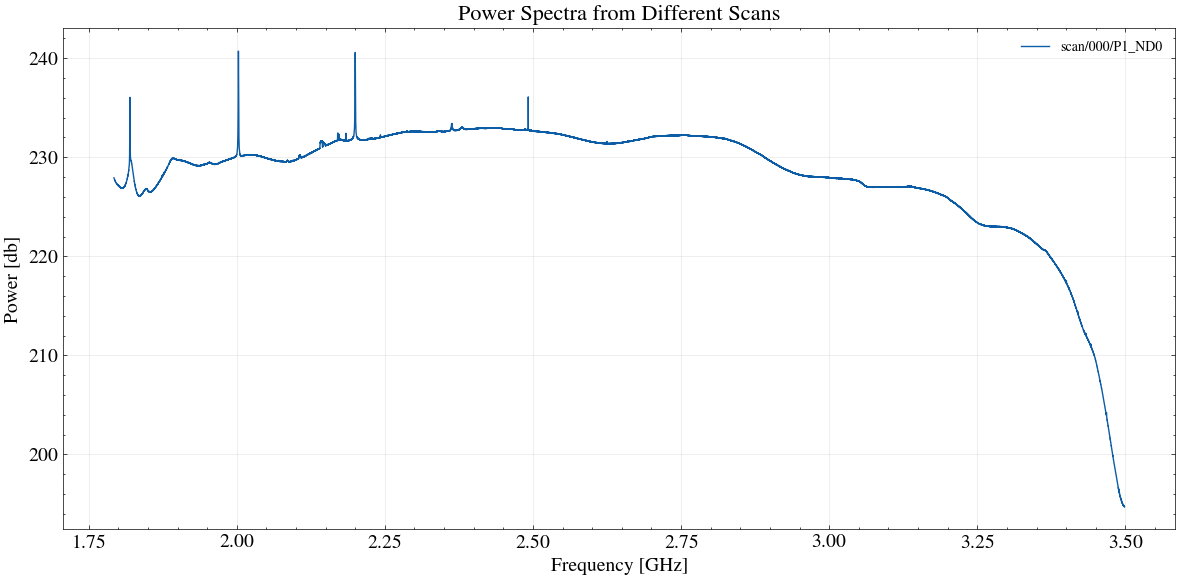

In [16]:


# List of groups you want to plot
groups = [
    "scan/000/P1_ND0",
    # "scan/000/P1_ND1",
    # "scan/001/P0_ND0",
    # "scan/001/P0_ND1",
    # "scan/001/P1_ND0",
    # "scan/001/P1_ND1"
]

# Open file and plot
with h5py.File(filename, "r") as f:
    plt.figure(figsize=(12, 6))

    for g in groups:
        # Load spectrum and frequency
        spectrum = f[f"{g}/spectrum"][:,1600:-60]       # shape: (ntime, nfreq); the 1600:-1 to flag bad data
        freq = f[f"{g}/frequency"][1600:-60] / 1e9    # convert Hz → GHz

        # Average over time axis
        mean_spectrum = 10*np.log10(np.mean(spectrum**2, axis=0)) # in dB

        # Plot
        plt.plot(freq, mean_spectrum, label=g)

    plt.xlabel("Frequency [GHz]")
    plt.ylabel("Power [db]")
    plt.title("Power Spectra from Different Scans", fontsize=16)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    plt.savefig


In [17]:
!pwd

/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset


# Baseline correction 


## For the baseline correction we will use the pybaseline library

The pybaselines library is a Python toolkit for removing smooth background trends (baselines) from spectral data, <br> 
and it can be very useful in radio astronomy for RFI characterization. In a power spectrum, the receiver bandpass <br> 
and system effects produce a smooth baseline, while RFI appears as sharp narrow or broad spikes above it. By applying <br>
 algorithms such as Asymmetric Least Squares (AsLS), airPLS, or SNIP, one can model and subtract the baseline, leaving <br>
  a detrended spectrum where RFI features stand out clearly. This makes it possible to apply statistical thresholds <br> 
  (e.g., sigma-clipping) to flag and count corrupted channels. In this way, pybaselines helps separate instrumental <br> 
  effects from true interference, providing a cleaner view of the spectrum and a quantitative measure of RFI contamination.


Source: https://pybaselines.readthedocs.io/en/latest/introduction.html

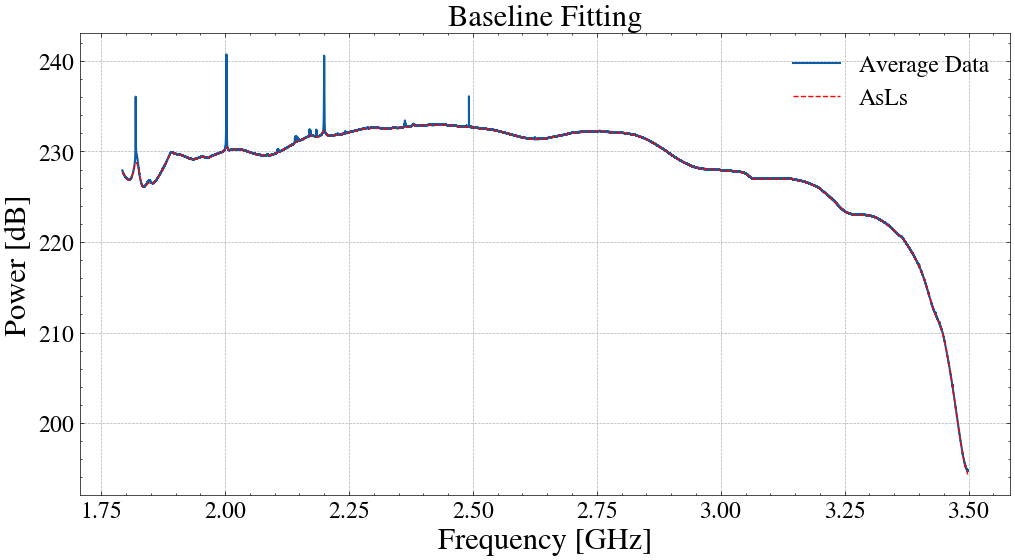

In [18]:
# baseline filter
baseline_fitter = Baseline(x_data=freq)
#bkg_1, params_1 = baseline_fitter.modpoly(mean_spectrum, poly_order=3)
bkg_2, params_2 = baseline_fitter.asls(mean_spectrum, lam=1e7, p=0.02)
bkg_3, params_3 = baseline_fitter.mor(mean_spectrum, half_window=30)


plt.figure(figsize=(12, 6))

plt.plot(freq, mean_spectrum, label='Average Data', lw=1.5)
#plt.plot(freq, bkg_1, '--', label='modpoly')
plt.plot(freq, bkg_2, '--', label='AsLs', color='red')
#plt.plot(freq, bkg_3, '--', label='mor')
#plt.xlim(1.75, 1.9)

plt.xlabel("Frequency [GHz]", fontsize=22)
plt.ylabel("Power [dB]", fontsize=22)
plt.title("Baseline Fitting", fontsize=22)
plt.grid(True, linestyle='--')
plt.legend(fontsize=17)
plt.xticks(fontsize=17)
plt.yticks(fontsize=17)

plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/baseline_fitting_comparison.png', dpi=300)
plt.savefig('/home/chavango/Master/SKAMPI_DATA/work_with_the_dataset/Plots/baseline_fitting_comparison.pdf', dpi=300)


The best baseline correction is "asis", which is the one we from now on we will be using 

In [19]:

def reduced_chi_square(y_obs, y_model, uncertainty=None, num_params=None):
    """
    Compute the reduced chi-square (χ²_red) for a model fit.

    Parameters
    ----------
    y_obs : array-like
        Observed data (e.g., your measured power spectrum)
    y_model : array-like
        Model predicted data (e.g., Gaussian or Lorentzian fit)
    uncertainty : array-like or float, optional
        Measurement uncertainty per point (σ). If None, use std(y_obs - y_model)
    num_params : int, optional
        Number of model parameters (for dof correction)
    """
    y_obs = np.asarray(y_obs)
    y_model = np.asarray(y_model)

    if uncertainty is None:
        # Estimate noise from residuals if not provided
        uncertainty = np.std(y_obs - y_model)

    chi2 = np.sum(((y_obs - y_model) / uncertainty)**2)

    # Reduced chi-square
    dof = len(y_obs) - (num_params if num_params is not None else 1)
    chi2_red = chi2 / dof
    return chi2_red


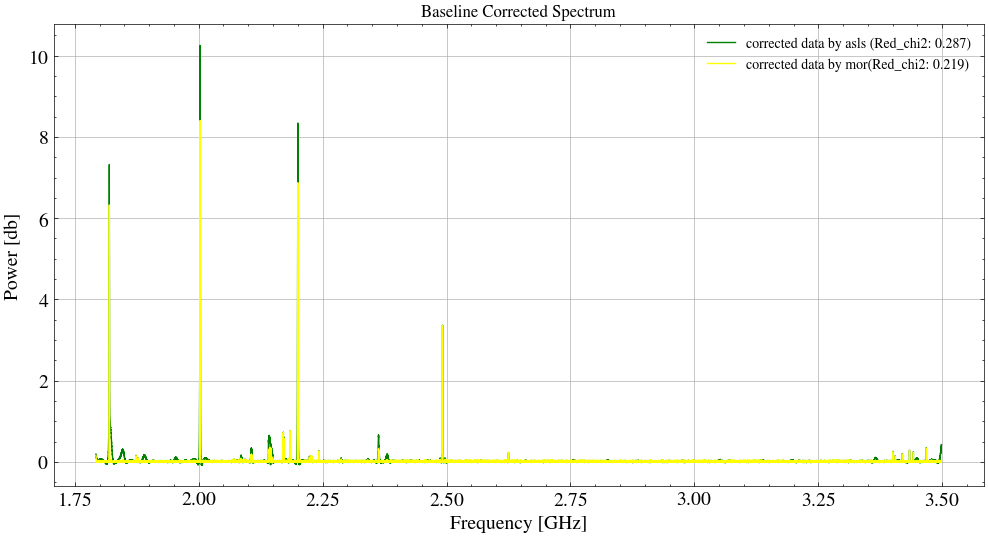

In [20]:
# baseline substraction
corrected_spectrum_asls = mean_spectrum - bkg_2
corrected_spectrum_mor = mean_spectrum - bkg_3


# Root Mean Square Error (RMSE) calculation
rmse_asls = np.sqrt(np.mean((mean_spectrum - bkg_2)**2))
rmse_mor = np.sqrt(np.mean((mean_spectrum - bkg_3)**2))

# Evaluate fit
chi2_red_bkg_2 = reduced_chi_square(mean_spectrum, corrected_spectrum_asls)
chi2_red_bkg_3 = reduced_chi_square(mean_spectrum, corrected_spectrum_mor)


# fig, ax = plt.subplots(1,2,figsize=(12, 6))

# ax[0].plot(freq, corrected_spectrum_asls, label='corrected data', lw=1.5)
# ax[0].set_xlabel("Frequency [GHz]")
# ax[0].set_ylabel("Power [db]")
# ax[0].set_title("Baseline Corrected Spectrum")
# ax[0].grid()


# ax[1].plot(freq, corrected_spectrum_mor, label='', lw=1.5)
# ax[1].set_xlabel("Frequency [GHz]")
# ax[1].set_ylabel("Power [db]")
# ax[1].set_title("Baseline Corrected Spectrum")
# ax[1].grid()

plt.figure(figsize=(12, 6))
plt.plot(freq, corrected_spectrum_asls, color='green',label=f'corrected data by asls (Red_chi2: {rmse_asls:.3f})')
plt.plot(freq, corrected_spectrum_mor, color='yellow', label=f'corrected data by mor(Red_chi2: {rmse_mor:.3f})')
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [db]")
plt.title("Baseline Corrected Spectrum")
plt.grid()
plt.legend()

The `ASLS` is a robust baseline correction method that finds the smooth lower envelope of a spectrum by penalizing <br>
positive peaks less than negative ones. It is one of the best choices when dealing with RFI in radio astronomy, <br>
 since it suppresses the bandpass trend while preserving the spikes you want to detect.

 What is ASLS?

ASLS = Asymmetric Least Squares smoothing

* It is a baseline correction algorithm that models the spectrum as a smooth baseline + peaks and tries to fit only the smooth part.

* It works by penalizing deviations asymmetrically:

* Negative deviations (data below the baseline) are penalized strongly.

* Positive deviations (peaks above the baseline, e.g. RFI spikes or spectral lines) are penalized weakly.

This ensures that the fitted curve follows the lower envelope of the spectrum, ignoring sharp upward peaks.

Detected peak frequencies (GHz): ['1.82', '2.003', '2.2', '2.492']


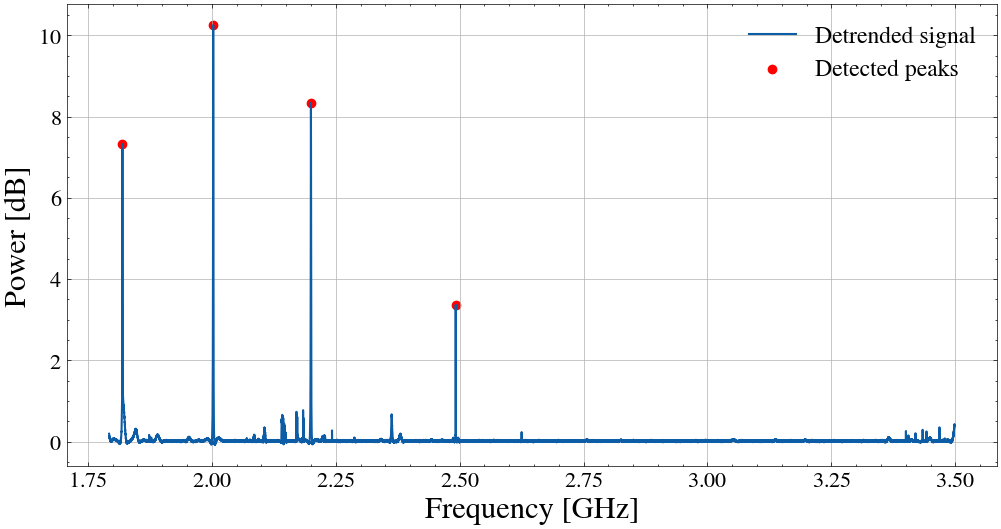

In [61]:
# lets find peaks
peaks, propreties = find_peaks(corrected_spectrum_asls, 
                              height=MAD(corrected_spectrum_asls) + np.std(corrected_spectrum_asls), 
                              distance=10,
                              prominence=1.5
                              )


plt.figure(figsize=(12, 6))
plt.plot(freq, corrected_spectrum_asls, label='Detrended signal', lw=1.5)
plt.scatter(freq[peaks], corrected_spectrum_asls[peaks], color='red', label='Detected peaks')
plt.xlabel("Frequency [GHz]", fontsize = 22)
plt.ylabel("Power [dB]", fontsize = 22)
#plt.title("Detected Peaks in Baseline Corrected Spectrum", )
plt.grid()
plt.yticks(fontsize=16)
plt.xticks(fontsize=16)
plt.legend(fontsize=17)

formatted_freqs = [f"{f:.4}" for f in freq[peaks]]
print(f"Detected peak frequencies (GHz): {formatted_freqs}")

We detected strong spikes in 4 different frequency. Now we need to identify instruments which operates on this bandwidth.

This frequency belong to S-band (2–4 GHz) region except 1.82 GHz which belong to the L-band (1–2 GHz), the the frequency <br>
detect on s-band is heavily used by satellite communication, mobile networks, and Wi-Fi.

### Inspect each frequecy detected

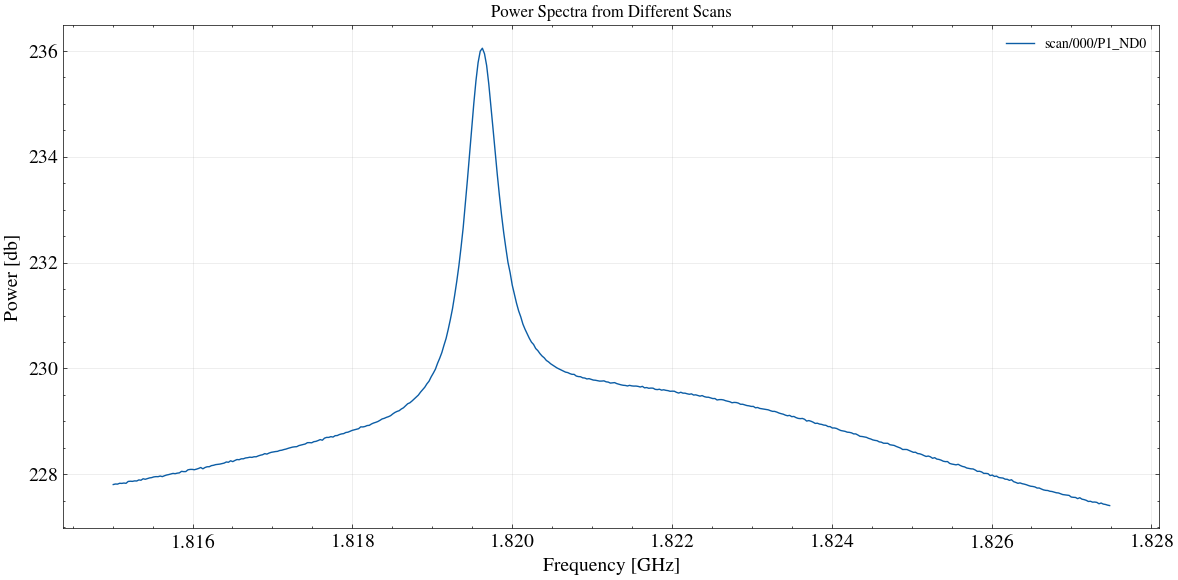

In [22]:
with h5py.File(filename, "r") as f:
    plt.figure(figsize=(12, 6))

    for g in groups:
        # Load spectrum and frequency
        spectrum = f[f"{g}/spectrum"][:,1600:-60]       # shape: (ntime, nfreq)
        freq = f[f"{g}/frequency"][1600:-60] /1e9   # convert Hz → MHz


        # Select indices for desired frequency range
        fmin, fmax = 1.815, 1.8275 # 1975, 2025   # MHz
        idx = (freq >= fmin) & (freq <= fmax)

        # Apply selection
        freq_selected = freq[idx]
        spectrum_selected = spectrum[:, idx]

        # Average over time axis
        mean_spectrum_selected = 10*np.log10(np.nanmean(spectrum_selected**2, axis=0)) # in dB

        # Plot
        plt.plot(freq_selected, mean_spectrum_selected, label=g)


        plt.xlabel("Frequency [GHz]")
        plt.ylabel("Power [db]")
        plt.title("Power Spectra from Different Scans")
        plt.legend()
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


In [23]:
freq[idx]

array([1.81500816, 1.81503487, 1.81506157, 1.81508827, 1.81511497,
       1.81514168, 1.81516838, 1.81519508, 1.81522179, 1.81524849,
       1.81527519, 1.8153019 , 1.8153286 , 1.8153553 , 1.815382  ,
       1.81540871, 1.81543541, 1.81546211, 1.81548882, 1.81551552,
       1.81554222, 1.81556892, 1.81559563, 1.81562233, 1.81564903,
       1.81567574, 1.81570244, 1.81572914, 1.81575584, 1.81578255,
       1.81580925, 1.81583595, 1.81586266, 1.81588936, 1.81591606,
       1.81594276, 1.81596947, 1.81599617, 1.81602287, 1.81604958,
       1.81607628, 1.81610298, 1.81612968, 1.81615639, 1.81618309,
       1.81620979, 1.8162365 , 1.8162632 , 1.8162899 , 1.8163166 ,
       1.81634331, 1.81637001, 1.81639671, 1.81642342, 1.81645012,
       1.81647682, 1.81650352, 1.81653023, 1.81655693, 1.81658363,
       1.81661034, 1.81663704, 1.81666374, 1.81669044, 1.81671715,
       1.81674385, 1.81677055, 1.81679726, 1.81682396, 1.81685066,
       1.81687737, 1.81690407, 1.81693077, 1.81695747, 1.81698

In [24]:
freq.shape

(63877,)

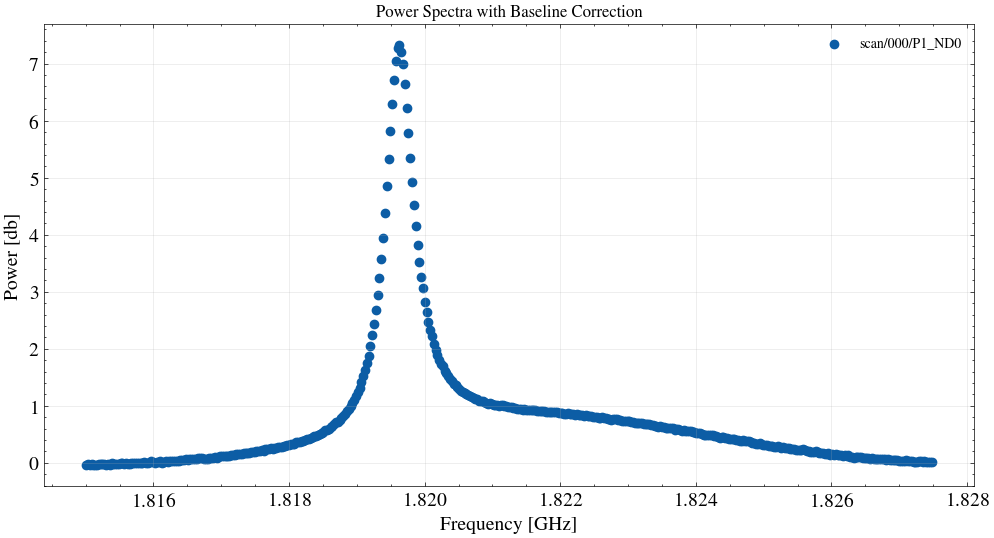

In [25]:


# Apply selection
freq_selected = freq[idx]
spectrum_selected_cor = corrected_spectrum_asls[idx]



# Plot
plt.figure(figsize=(12, 6))
plt.scatter(freq_selected, spectrum_selected_cor, label=g)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [db]")
plt.title("Power Spectra with Baseline Correction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Best-fit parameters:
Amplitude = 6.072
Mean      = 1.820
Stddev    = 0.000
Baseline  = 0.426
FWHM = 0.001


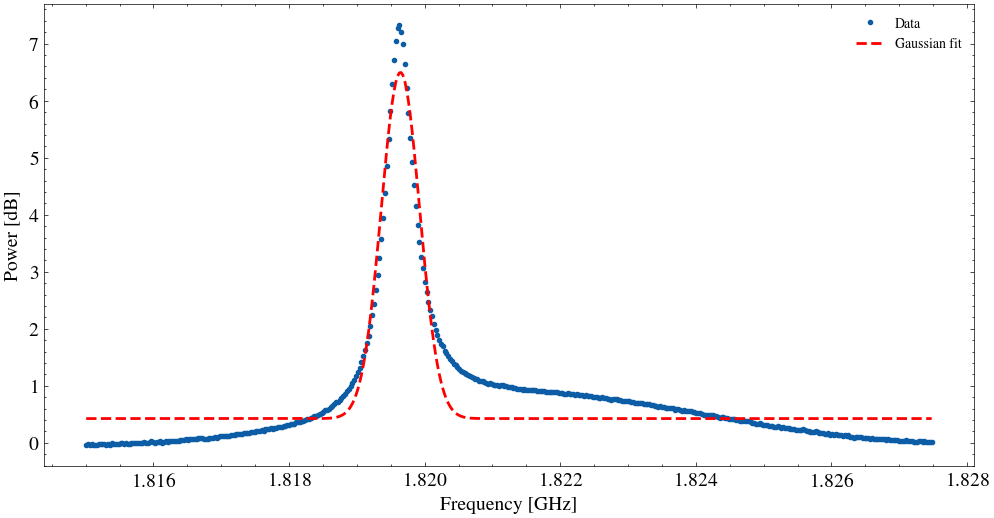

In [26]:

# --- Initial guess ---
# amplitude: 
A0 = spectrum_selected_cor.max() - spectrum_selected_cor.min() # where we have the maximum values of the plot
# mean: frequency at maximum
mu0 = freq_selected[spectrum_selected_cor.argmax()]
# stddev: 
#sigma0 = np.std(freq_selected)
sigma0 = (freq_selected.max() - freq_selected.min())/2.355

# constant
C0 = spectrum_selected_cor.min()



# Define model: Gaussian + Constant
g_init = models.Gaussian1D(amplitude=A0, mean=mu0, stddev=sigma0) + models.Const1D(amplitude=C0)

# --- Fit ---
fitter = fitting.LevMarLSQFitter()
g_fit = fitter(g_init, freq_selected, spectrum_selected_cor)

# --- Extract fitted parameters ---
print("Best-fit parameters:")
print(f"Amplitude = {g_fit.amplitude_0.value:.3f}")
print(f"Mean      = {g_fit.mean_0.value:.3f}")
print(f"Stddev    = {g_fit.stddev_0.value:.3f}")
print(f"Baseline  = {g_fit.amplitude_1.value:.3f}")

# FWHM = 2.355 * sigma
fwhm = 2.355 * g_fit.stddev_0.value
print(f"FWHM = {fwhm:.3f}")


# --- Plot ---
plt.figure(figsize=(12, 6))
plt.plot(freq_selected, spectrum_selected_cor, '.',label="Data")
plt.plot(freq_selected, g_fit(freq_selected), 'r--', lw=2, label="Gaussian fit")
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [dB]")   # adjust units
plt.legend()
plt.show()

# Use the method `Tied Constraints`

Best-fit parameters:
Amplitude = -2.320
Mean      = 1.831
Stddev    = 0.000
Baseline  = 7.151
FWHM = 0.001


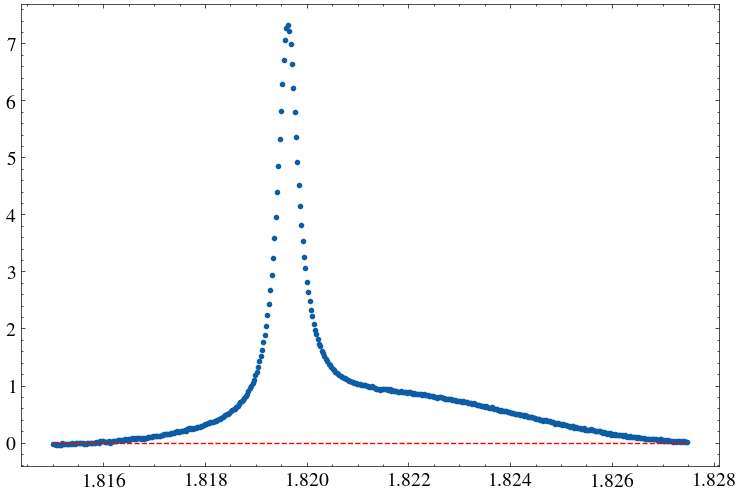

In [27]:

# create a gaussian model for each 
g1 = models.Gaussian1D(amplitude=A0, mean=mu0, stddev=sigma0)
g2 = models.Gaussian1D(amplitude=1, mean=1.81, stddev=np.std(freq_selected))

# create a polynomial model to fit
mean_power = spectrum_selected_cor.mean()
count = np.where(spectrum_selected_cor > mean_power, mean_power, spectrum_selected_cor)
linfitter = fitting.LinearLSQFitter()
poly_cont = linfitter(models.Polynomial1D(1), freq_selected, count)

# Create a compound model for the four emission lines and the continuum.
model = g1 + g2

# Simultaneously fit all the emission lines and continuum.
fitter_TRF = fitting.TRFLSQFitter()
fitted_model_TRF = fitter_TRF(model, freq_selected, spectrum_selected_cor)
fitted_lines = fitted_model_TRF(freq_selected)


# --- Extract fitted parameters ---
print("Best-fit parameters:")
print(f"Amplitude = {fitted_model_TRF.amplitude_0.value:.3f}")
print(f"Mean      = {fitted_model_TRF.mean_0.value:.3f}")
print(f"Stddev    = {fitted_model_TRF.stddev_0.value:.3f}")
print(f"Baseline  = {fitted_model_TRF.amplitude_1.value:.3f}")

# FWHM = 2.355 * sigma
fwhm0 = 2.355 * fitted_model_TRF.stddev_0.value
print(f"FWHM = {fwhm:.3f}")


# Plot the data and the fitted model
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(freq_selected, spectrum_selected_cor,'.', label="Data")
ax.plot(freq_selected, fitted_lines, 'r--',label="Fitted Model")

In [28]:
print(fitted_model_TRF)

Model: CompoundModel
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Expression: [0] + [1]
Components: 
    [0]: <Gaussian1D(amplitude=-2.32017124, mean=1.83064673, stddev=0.00002623)>

    [1]: <Gaussian1D(amplitude=7.1514739, mean=1.76729681, stddev=0.0035923)>
Parameters:
       amplitude_0           mean_0      ...       mean_1            stddev_1      
    ------------------ ----------------- ... ----------------- --------------------
    -2.320171240804994 1.830646725984088 ... 1.767296806191497 0.003592298446834083


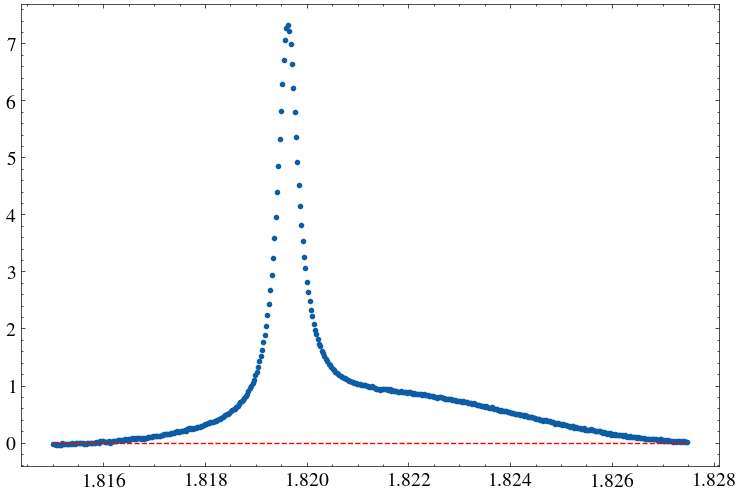

In [29]:

# create a gaussian model for each 
g1 = models.Gaussian1D(amplitude=A0, mean=mu0, stddev=sigma0)
g2 = models.Gaussian1D(amplitude=1.2, mean=1.82,stddev=np.std(freq_selected))

# Create a compound model for the four emission lines and the continuum.
compound_model = g1 + g2
compound_model.mean_0.max = mu0 + 0.5
compound_model.mean_0.min = mu0 - 0.5


fitter = fitting.LevMarLSQFitter()
compound_fit_bounded = fitter(compound_model, freq_selected, spectrum_selected_cor)


# Plot the data and the fitted model
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(freq_selected, spectrum_selected_cor,'.', label="Data")
ax.plot(freq_selected, fitted_lines, 'r--',label="Fitted Model")


In [30]:
print(compound_fit_bounded.mean_0)


Parameter('mean', value=1.837917493609271, bounds=(1.3196277618408203, 2.3196277618408203))


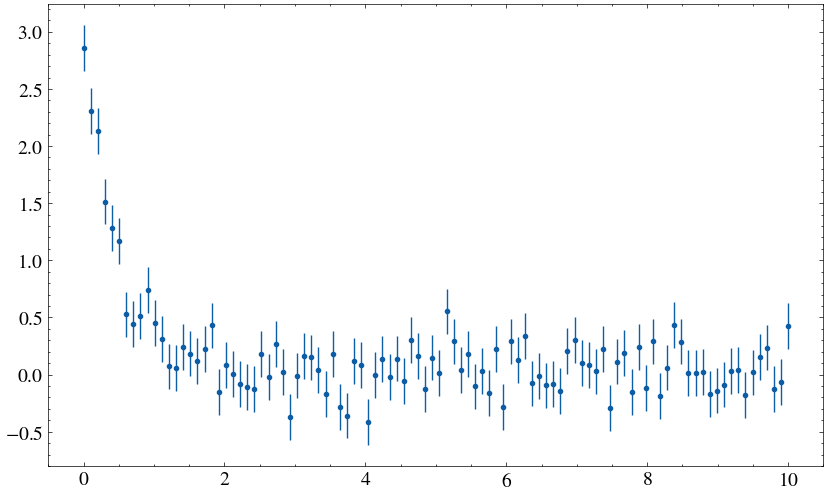

In [31]:
x1 = np.linspace(0, 10, 100)

a = 3
b = -2
c = 0
y1 = a * np.exp(b * x1 + c)
y1 += np.random.normal(0.0, 0.2, x1.shape)
y1_err = np.ones(x1.shape) * 0.2


plt.figure(figsize=(10, 6))
plt.errorbar(x1, y1, yerr=y1_err, fmt=".")
plt.show()

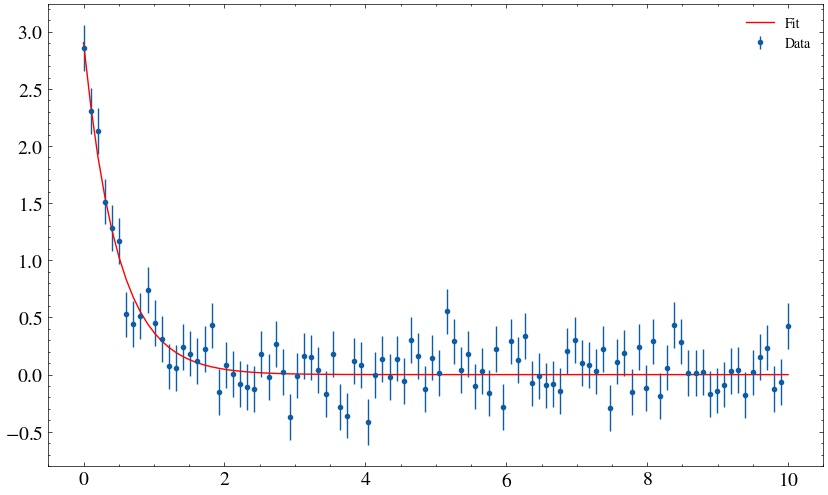

In [32]:

exp_init = models.Exponential1D(amplitude=3.0, tau=-0.5)  # tau = 1/k

fitter = fitting.LevMarLSQFitter()
exp_fit = fitter(exp_init, x1, y1, weights=1.0 / y1_err**2)

# Plot
plt.figure(figsize=(10, 6))
plt.errorbar(x1, y1, yerr=y1_err, fmt=".", label="Data")
plt.plot(x1, exp_fit(x1), "r-", label="Fit")
plt.legend()
plt.show()

Component 0: mean=1.819649 GHz, FWHM=0.80 MHz, ~30.0 channels
Component 1: mean=1.819649 GHz, FWHM=0.00 MHz, ~0.0 channels


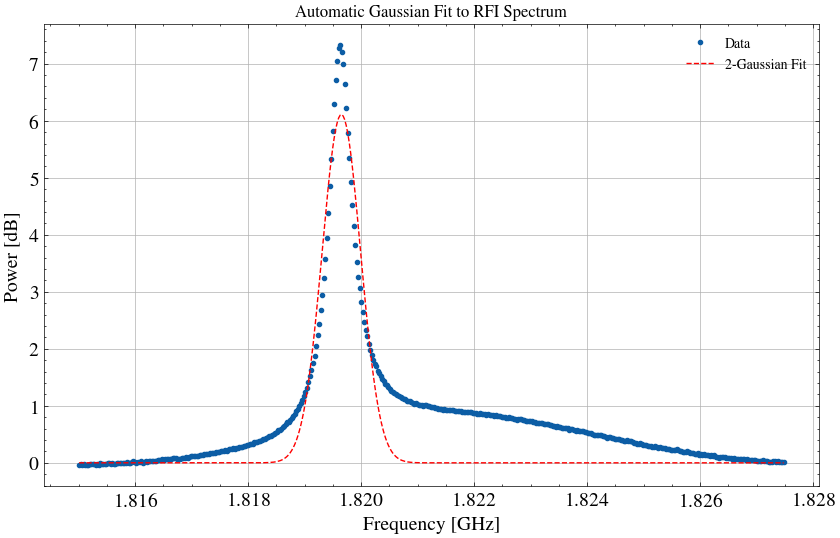

In [33]:

# --- 1) Automatic initial guess ---
# Find peak (narrow Gaussian)
peak_idx = np.argmax(spectrum_selected_cor)
peak_amp = spectrum_selected_cor[peak_idx]
peak_freq = freq_selected[peak_idx]

# Estimate stddev of narrow Gaussian from resolution
delta_f = freq_selected[1] - freq_selected[0]   # channel width
sigma_narrow = 5 * delta_f       # a few channels wide

# Estimate broad Gaussian
median_amp = np.median(spectrum_selected_cor)
sigma_broad = 0.01               # ~10 MHz broad feature (tweak if needed)
amp_broad = (peak_amp - median_amp) / 5.0  # smaller amplitude than narrow

# --- 2) Define models ---
g_narrow = models.Gaussian1D(amplitude=peak_amp, mean=peak_freq, stddev=sigma_narrow)
g_broad  = models.Gaussian1D(amplitude=amp_broad, mean=peak_freq, stddev=sigma_broad)

# Tie the broad Gaussian mean to the narrow one (they share the same center)
def tie_means(model):
    return model.mean_0
g_broad.mean.tied = tie_means

# Combine them
model_init = g_narrow + g_broad

# 3) Fit ---
fitter_Lev = fitting.LevMarLSQFitter()
fitted_model_Lev = fitter_Lev(model_init, freq_selected, spectrum_selected_cor)

# --- 4) Extract results ---
for i, comp in enumerate(fitted_model_Lev):
    mean = comp.mean.value
    sigma = comp.stddev.value
    fwhm = 2.355 * sigma
    chans = fwhm / delta_f
    print(f"Component {i}: mean={mean:.6f} GHz, FWHM={fwhm*1e3:.2f} MHz, ~{chans:.1f} channels")

# --- 5) Plot ---
plt.figure(figsize=(10,6))
plt.plot(freq_selected, spectrum_selected_cor, '.', label="Data")
plt.plot(freq_selected, fitted_model_Lev(freq_selected), 'r--', label="2-Gaussian Fit")
#plt.plot(freq_selected, fitted_model[0](freq_selected), 'g:', label="Narrow Gaussian")
#plt.plot(freq_selected, fitted_model[1](freq_selected), 'm:', label="Broad Gaussian")
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [dB]")
plt.legend()
plt.title("Automatic Gaussian Fit to RFI Spectrum")
plt.grid()


--> Let's evaluate try a different model using chi-square

In [34]:
print(f'{fitted_model_Lev} \n ')


Model: CompoundModel
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Expression: [0] + [1]
Components: 
    [0]: <Gaussian1D(amplitude=6.10869154, mean=1.81964904, stddev=0.00034028)>

    [1]: <Gaussian1D(amplitude=0.82435303, mean=1.81964904, stddev=0.)>
Parameters:
       amplitude_0          mean_0       ...        stddev_1       
    ----------------- ------------------ ... ----------------------
    6.108691542042321 1.8196490448354614 ... 1.1754943508222875e-38 
 


In [35]:
def reduce_chi_square(model,frequency,power, yerr=None):

    """
    Compute reduced chi-square for a fitted astropy model.

    fit_model : astropy model (already fitted)
    frequency     : array, independent variable (frequency)
    power     : array, observed data (power)
    yerr  : array or float, optional measurement uncertainties.
            If None, use std of y as uniform error.
    """

    fit_model = model(power)
    residuals = power - fit_model

    if yerr is None:
        yerr = np.std(power)
        


    chi2 = np.sum(residuals / yerr**2)   
    chi2_red = chi2 / (len(frequency) - len(model.param_names))

    return chi2_red

In [36]:
# fit a different model
chi2_Lev = reduce_chi_square(fitted_model_Lev,freq,spectrum_selected_cor)
chi2_TRF = reduce_chi_square(fitted_model_TRF,freq,spectrum_selected_cor)
print(f'Chi-square for TRFLSQFitter model: {chi2_TRF} \nChi-square for LevMarLSQFitter model: {chi2_Lev}')


Chi-square for TRFLSQFitter model: 0.003752323167669997 
Chi-square for LevMarLSQFitter model: 0.003752527641858359


In [37]:
def reduce_chi_square2(model,frequency,power, yerr):

    """
    Compute reduced chi-square for a fitted astropy model.

    fit_model : astropy model (already fitted)
    frequency     : array, independent variable (frequency)
    power     : array, observed data (power)
    yerr  : array or float, optional measurement uncertainties.
            If None, use std of y as uniform error.
    """

    fit_model = model(power)
    residuals = power - fit_model

    uncertities = np.std(yerr)

    chi2 = np.sum(residuals / uncertities**2)   
    chi2_red = chi2 / (len(frequency) - len(model.param_names))

    return chi2_red

In [38]:
mean_spectrum.shape

(63877,)

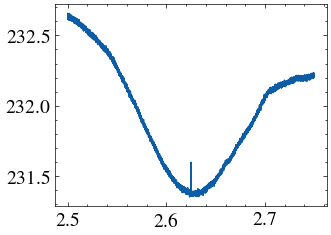

In [39]:
# Select indices for desired frequency range
fmin, fmax = 2.5, 2.75 
idx1 = (freq >= fmin) & (freq <= fmax)

spec = mean_spectrum[idx1]
fr = freq[idx1]
plt.plot(fr,spec)


In [40]:
chi_Lev = reduce_chi_square2(fitted_model_Lev,freq,spectrum_selected_cor, spec)
chi_Lev


np.float64(0.03818958042916608)

In [41]:
def RMSE(power,model):
    fit_model=model(power)
    return np.sqrt(np.mean((power-fit_model)**2))

In [42]:

def fit_gaussian_window(freq, power, plot=True, residual_threshold=0.2):
    """
    Fit Gaussian(s) to a given frequency window.
    
    Parameters
    ----------
    freq : array
        Frequency array (subset/window).
    power : array
        Power spectrum (subset/window).
    plot : bool
        If True, plots data and fit.
    residual_threshold : float
        Threshold of normalized residuals to decide if second Gaussian is needed.
    
    Returns
    -------
    fitted_model : astropy.modeling compound model
        The best-fit model (1 or 2 Gaussians).
    """
    # Step 1: Initial guess for single Gaussian ----
    peak_idx = np.argmax(power)
    peak_amp = power[peak_idx]
    peak_freq = freq[peak_idx]
    delta_f = np.diff(freq).mean()  # channel width
    sigma_guess = 5 * delta_f

    g1 = models.Gaussian1D(amplitude=peak_amp, mean=peak_freq, stddev=sigma_guess)

    # ---- Step 2: Fit single Gaussian ----
    fitter = fitting.LevMarLSQFitter()
    g1_fit = fitter(g1, freq, power)

    # Compute residuals
    residuals = power - g1_fit(freq)
    norm_resid = np.std(residuals) / np.max(power)
    print(f'The normalized residual: {norm_resid}')
    
    # Compute the RMSE
    rmse = RMSE(power,g1_fit)
    print(f'The Root Mean Square Error: {rmse}')

    # ---- Step 3: Check if second Gaussian is needed ----
    if norm_resid > residual_threshold:
        # Add broad Gaussian tied to the same mean
        sigma_broad = (freq.max() - freq.min()) / 5  # broad guess
        amp_broad = (np.max(power) - np.median(power)) / 5.0
        g2 = models.Gaussian1D(amplitude=amp_broad, mean=peak_freq, stddev=sigma_broad)

        # Tie the broad Gaussian mean to the narrow one
        g2.mean.tied = lambda model: model.mean_0

        model_init = g1 + g2
        fitted_model = fitter(model_init, freq, power)
    else:
        fitted_model = g1_fit


    # ---- Step 4: Plot results ----
    if plot:
        plt.figure(figsize=(8, 5))
        plt.plot(freq, power, 'k-', label="Data")
        plt.plot(freq, fitted_model(freq), 'r--', label="Best Fit")
        if hasattr(fitted_model, 'submodel_names'):
            for i, comp in enumerate(fitted_model):
                plt.plot(freq, comp(freq), '--', label=f"Gaussian {i+1}")
        else:
            plt.plot(freq, fitted_model(freq), 'b:', label="Single Gaussian")
        plt.xlabel("Frequency")
        plt.ylabel("Power")
        plt.legend()
        plt.show()

    return fitted_model



The normalized residual: 0.037176687636977714
The Root Mean Square Error: 3.318868386769297


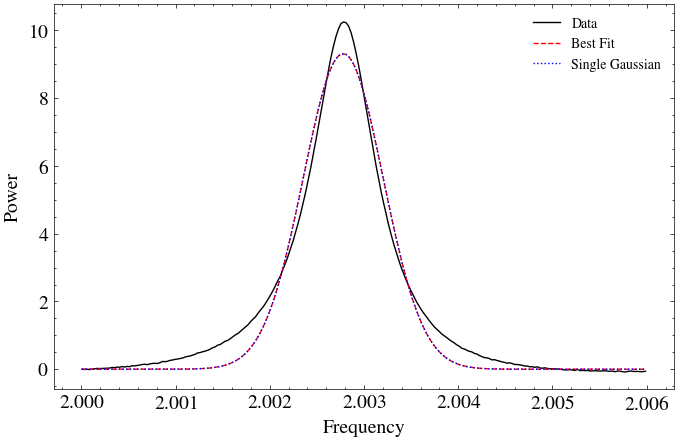

In [43]:
# -----------------------
# Example usage:
# Assume freq, power are your spectrum arrays
# Select a window around a suspected RFI line
# -----------------------
mask1 = (freq > 1.81) & (freq < 1.83) 
mask2 = (freq > 2.00) & (freq < 2.006) 
mask3 = (freq > 2.197) & (freq < 2.203) 
mask4 = (freq > 2.491) & (freq < 2.493) 

fitted = fit_gaussian_window(freq[mask2], corrected_spectrum_asls[mask2])



# '2.003'

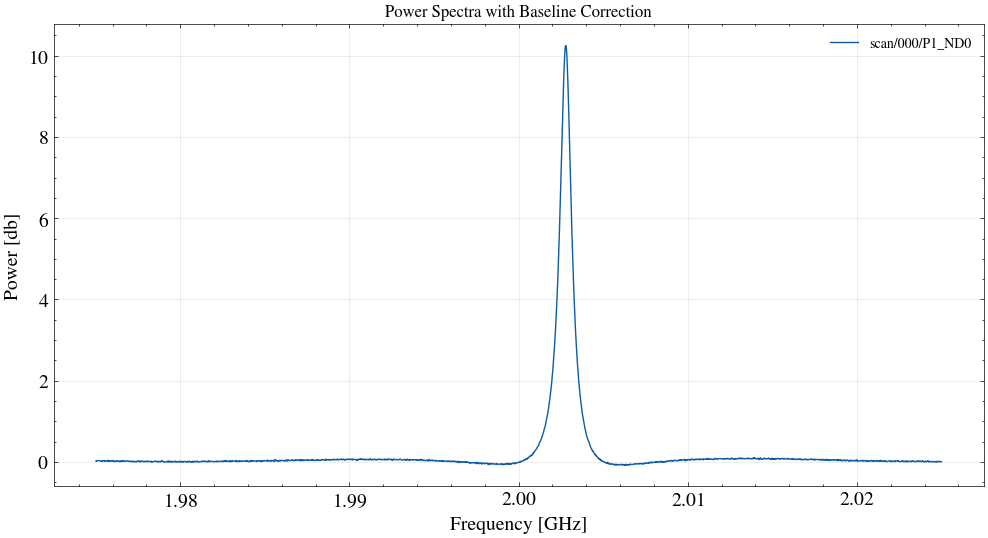

In [44]:

# Select ithe second spike

fmin, fmax = 1.975, 2.025   # MHz
idx = (freq >= fmin) & (freq <= fmax)

# Apply selection
freq_selected_nd = freq[idx]
spectrum_selected_cor_nd = corrected_spectrum_asls[idx]



# Plot
plt.figure(figsize=(12, 6))
plt.plot(freq_selected_nd, spectrum_selected_cor_nd, label=g)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [db]")
plt.title("Power Spectra with Baseline Correction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [45]:

# --- Initial guess ---
# amplitude: 
A1 = spectrum_selected_cor_nd.max() - spectrum_selected_cor_nd.min() # where we have the maximum values of the plot
# mean: frequency at maximum
mu1 = freq_selected_nd[spectrum_selected_cor_nd.argmax()]
# stddev: 
sigma1 = (freq_selected_nd.max() - freq_selected_nd.min())/20
# constant
C1 = np.median(spectrum_selected_cor_nd)

# Define model: Gaussian + Constant
g_init1 = models.Gaussian1D(amplitude=A1, mean=mu1, stddev=sigma1) + models.Const1D(amplitude=C1)

# --- Fit ---
fitter = fitting.LevMarLSQFitter()
g_fit1 = fitter(g_init1, freq_selected_nd, spectrum_selected_cor_nd)

# --- Extract fitted parameters ---
print("Best-fit parameters:")
print(f"Amplitude = {g_fit1.amplitude_0.value:.3f}")
print(f"Mean      = {g_fit1.mean_0.value:.3f}")
print(f"Stddev    = {g_fit1.stddev_0.value:.3f}")
print(f"Baseline  = {g_fit1.amplitude_1.value:.3f}")

# FWHM = 2.355 * sigma
fwhm = 2.355 * g_fit1.stddev_0.value
print(f"FWHM = {fwhm:.3f}")


Best-fit parameters:
Amplitude = 9.292
Mean      = 2.003
Stddev    = 0.000
Baseline  = 0.048
FWHM = 0.001


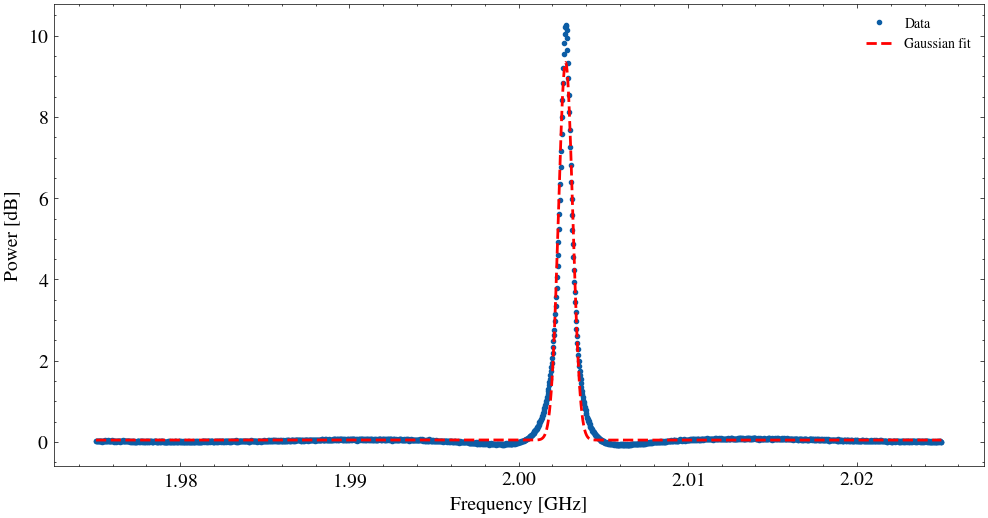

In [46]:
# --- Plot ---
plt.figure(figsize=(12, 6))
plt.plot(freq_selected_nd, spectrum_selected_cor_nd, '.',label="Data")
plt.plot(freq_selected_nd, g_fit1(freq_selected_nd), 'r--', lw=2, label="Gaussian fit")
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [dB]")   # adjust units
plt.legend()
plt.show()

# '2.2'

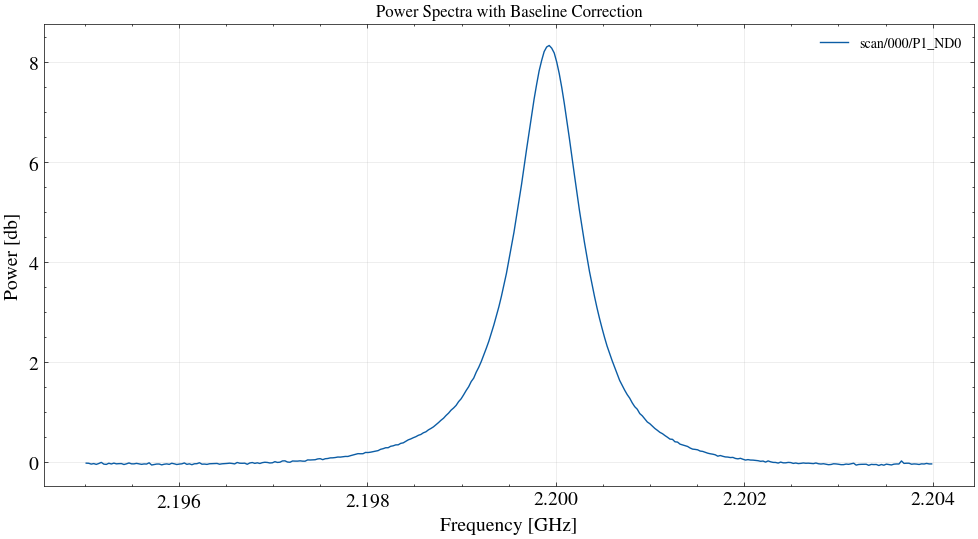

In [47]:

# Select indices for desired frequency range
fmin, fmax = 2.195, 2.204   # MHz
idx = (freq >= fmin) & (freq <= fmax)

# Apply selection
freq_selected_rd = freq[idx]
spectrum_selected_cor_rd = corrected_spectrum_asls[idx]



# Plot
plt.figure(figsize=(12, 6))
plt.plot(freq_selected_rd, spectrum_selected_cor_rd, label=g)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [db]")
plt.title("Power Spectra with Baseline Correction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Best-fit parameters:
Amplitude = 7.531
Mean      = 2.200
Stddev    = 0.000
Baseline  = 0.111
FWHM = 0.001


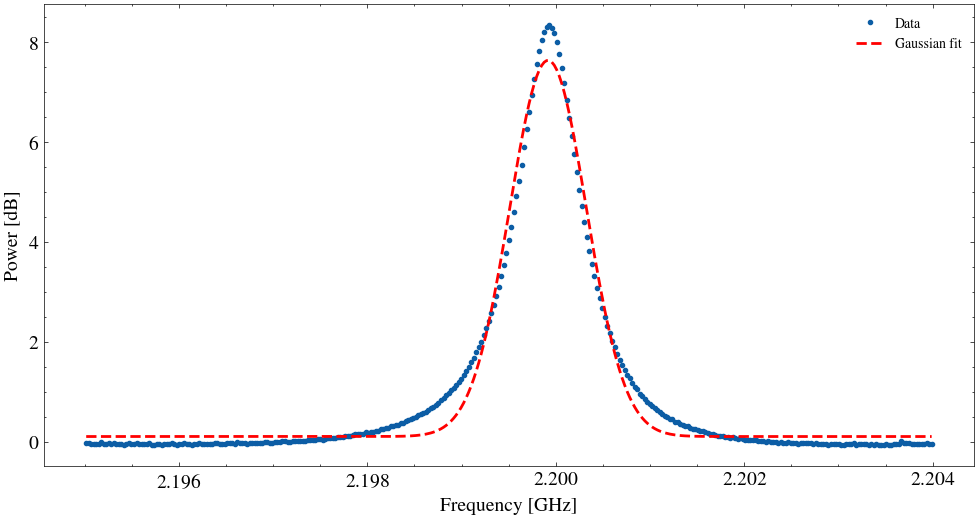

In [48]:

# --- Initial guess ---
# amplitude: 
A3 = spectrum_selected_cor_rd.max() - spectrum_selected_cor_rd.min() # where we have the maximum values of the plot
# mean: frequency at maximum
mu3 = freq_selected_rd[spectrum_selected_cor_rd.argmax()]
# stddev: 
sigma3 = (freq_selected_rd.max() - freq_selected_rd.min())/20
# constant
C3 = np.median(spectrum_selected_cor_rd)

# Define model: Gaussian + Constant
g_init3 = models.Gaussian1D(amplitude=A3, mean=mu3, stddev=np.std(freq_selected_rd)) + models.Const1D(amplitude=C3)

# --- Fit ---
fitter3 = fitting.LevMarLSQFitter()
g_fit3 = fitter3(g_init3, freq_selected_rd, spectrum_selected_cor_rd)

# --- Extract fitted parameters ---
print("Best-fit parameters:")
print(f"Amplitude = {g_fit3.amplitude_0.value:.3f}")
print(f"Mean      = {g_fit3.mean_0.value:.3f}")
print(f"Stddev    = {g_fit3.stddev_0.value:.3f}")
print(f"Baseline  = {g_fit3.amplitude_1.value:.3f}")

# FWHM = 2.355 * sigma
fwhm = 2.355 * g_fit3.stddev_0.value
print(f"FWHM = {fwhm:.3f}")

# --- Plot ---
plt.figure(figsize=(12, 6))
plt.plot(freq_selected_rd, spectrum_selected_cor_rd, '.',label="Data")
plt.plot(freq_selected_rd, g_fit3(freq_selected_rd), 'r--', lw=2, label="Gaussian fit")
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [dB]")   # adjust units
plt.legend()
plt.show()

In [49]:
spec

array([232.63756, 232.63904, 232.62952, ..., 232.21046, 232.21739,
       232.22679], shape=(9362,), dtype=float32)

In [50]:
mask_good = np.isfinite(freq) & np.isfinite(spectrum)


Center frequency = 1.582020 GHz
FWHM = 8066006550.383 MHz
Estimated RFI bandwidth ≈ 8066006550.383 MHz


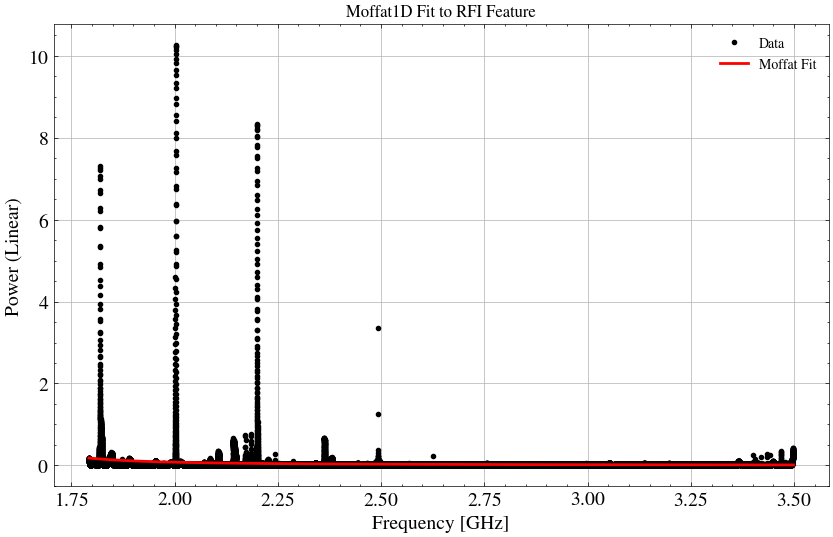

In [51]:


# Select your data
spec = corrected_spectrum_asls[idx]
freq_selected = freq[idx]


# ---------------------------
# 2) Clean the data
# ---------------------------
mask_good = np.isfinite(freq) & np.isfinite(spectrum)
freq = freq[mask_good[0]]
spec = corrected_spectrum_asls[mask_good[1]]

# --- Option A: work in linear power scale ---
# If your spectrum is already linear (not dB), just clip small negatives:
spec_lin = np.clip(spec, 1e-6, None)

# ---------------------------
# 3) Initial guess for Moffat parameters
# ---------------------------
peak_idx = np.argmax(spec_lin)
amp_init = spec_lin[peak_idx]
center_init = freq[peak_idx]
delta_f = np.median(np.diff(freq))

# alpha roughly ~ width scale (Hz)
alpha_init = 20 * delta_f
# gamma controls the shape; 2-3 gives Gaussian-like wings
gamma_init = 2.0

moffat_init = models.Moffat1D(amplitude=amp_init, x_0=center_init,
                              alpha=alpha_init, gamma=gamma_init)

# ---------------------------
# 4) Fit the model
# ---------------------------
fitter = fitting.LevMarLSQFitter()
moffat_fit = fitter(moffat_init, freq, spec_lin)

# ---------------------------
# 5) Compute FWHM and bandwidth
# ---------------------------
alpha = moffat_fit.alpha.value
gamma = moffat_fit.gamma.value
fwhm = 2 * alpha * np.sqrt(2 ** (1 / gamma) - 1)
bandwidth = fwhm * 1e3  # GHz → MHz if freq in GHz

print(f"Center frequency = {moffat_fit.x_0.value:.6f} GHz")
print(f"FWHM = {fwhm*1e3:.3f} MHz")
print(f"Estimated RFI bandwidth ≈ {bandwidth:.3f} MHz")

# ---------------------------
# 6) Plot result
# ---------------------------
plt.figure(figsize=(10,6))
plt.plot(freq, spec_lin, 'k.', label='Data')
plt.plot(freq, moffat_fit(freq), 'r-', lw=2, label='Moffat Fit')
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power (Linear)")
plt.legend()
plt.title("Moffat1D Fit to RFI Feature")
plt.grid(True)
plt.show()


# '2.492'

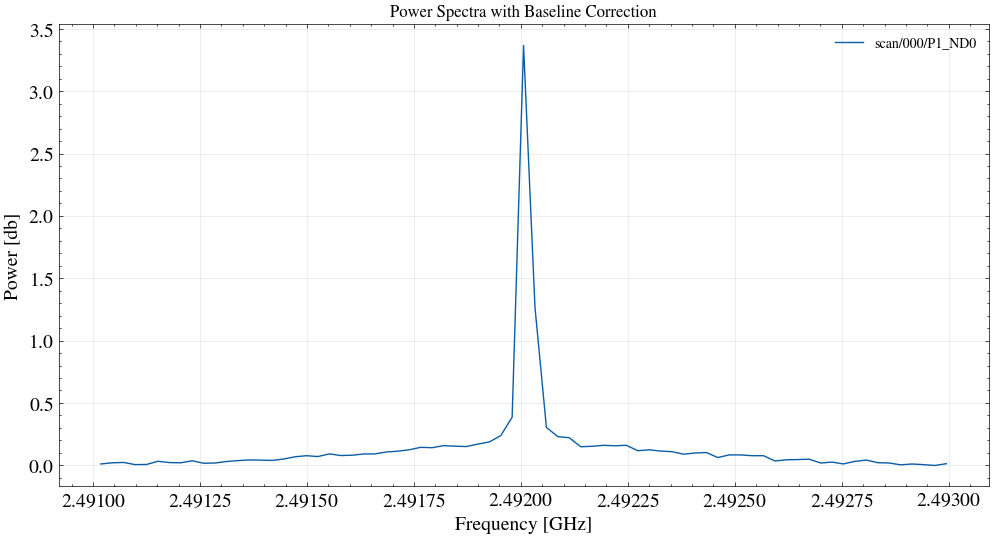

In [52]:
# Select the fourth spike

fmin, fmax = 2.491, 2.493   # MHz
idx = (freq >= fmin) & (freq <= fmax)

# Apply selection
freq_selected_th = freq[idx]
spectrum_selected_cor_th = corrected_spectrum_asls[idx]



# Plot
plt.figure(figsize=(12, 6))
plt.plot(freq_selected_th, spectrum_selected_cor_th, label=g)
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [db]")
plt.title("Power Spectra with Baseline Correction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


Best-fit parameters:
Amplitude = 3.506
Mean      = 2.492
Stddev    = 0.000
Baseline  = 0.080
FWHM = 0.000


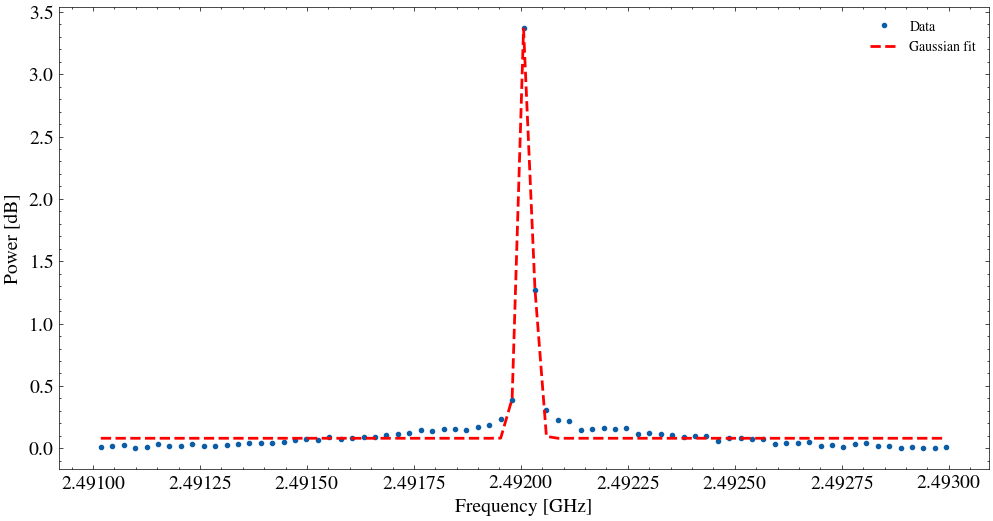

In [53]:

# --- Initial guess ---
# amplitude: 
A4 = spectrum_selected_cor_th.max() - spectrum_selected_cor_th.min() # where we have the maximum values of the plot
# mean: frequency at maximum
mu4 = freq_selected_th[spectrum_selected_cor_th.argmax()]
# stddev: 
sigma4 = (freq_selected_th.max() - freq_selected_th.min())/25
# constant
C4 = np.median(spectrum_selected_cor_th)

# Define model: Gaussian + Constant
g_init4 = models.Gaussian1D(amplitude=A4, mean=mu4, stddev=sigma4) + models.Const1D(amplitude=C4)

# --- Fit ---
fitter4 = fitting.LevMarLSQFitter()
g_fit4 = fitter4(g_init4, freq_selected_th, spectrum_selected_cor_th)

# --- Extract fitted parameters ---
print("Best-fit parameters:")
print(f"Amplitude = {g_fit4.amplitude_0.value:.3f}")
print(f"Mean      = {g_fit4.mean_0.value:.3f}")
print(f"Stddev    = {g_fit4.stddev_0.value:.3f}")
print(f"Baseline  = {g_fit4.amplitude_1.value:.3f}")

# FWHM = 2.355 * sigma
fwhm = 2.355 * g_fit4.stddev_0.value
print(f"FWHM = {fwhm:.3f}")

# --- Plot ---
plt.figure(figsize=(12, 6))
plt.plot(freq_selected_th, spectrum_selected_cor_th, '.',label="Data")
plt.plot(freq_selected_th, g_fit4(freq_selected_th), 'r--', lw=2, label="Gaussian fit")
plt.xlabel("Frequency [GHz]")
plt.ylabel("Power [dB]")   # adjust units
plt.legend()
plt.show()


# Calculating the Number of Channels from FWHM

The number of channels spanned by your line depends on the **channel width** of your spectrum.


## Step 1: Relation between FWHM and channel spacing

$$ 
N_{\text{chan}} = \frac{\text{FWHM}}{\Delta f}
 $$

where:

- **FWHM** = width of your line (in frequency units, e.g., GHz or MHz)  
- **Δf** = frequency resolution, i.e., channel width (same units as FWHM)  


## Step 2: Example with your case

You said:

$$
\text{FWHM} = 0.001 \ \text{GHz} = 1 \ \text{MHz}
$$

If your channel width is, say, **3 kHz** (MeerKAT common mode), then:

$$
N_{\text{chan}} = \frac{1 \ \text{MHz}}{3 \ \text{kHz}} = \frac{1000}{3} \approx 333
$$

So your line would span **~333 channels**.


# Frequency Resolution in a Power Spectrum



## 1. General definition

The **frequency resolution** (Δf, i.e., channel width) of a power spectrum is:

$$
\Delta f = \frac{f_{\text{sample}}}{N_{\text{FFT}}}
$$

where:

- $ f_{\text{sample}} $ = total sampled bandwidth (Hz)  
- $ N_{\text{FFT}} $ = number of points in the Fourier transform (FFT length)  



## 2. From your data arr
If you already have the **frequency axis** in your spectrum (e.g. `freq` array),  
you don’t need to know FFT details. You can just compute the spacing between two adjacent frequency bins.


In [54]:
delta_f = np.mean(np.diff(freq))  # frequency resolution per channel




print(f"Frequency resolution = {delta_f/1e9} [GHz]")

Frequency resolution = 2.6702880859375e-14 [GHz]


In [55]:
# number off channels afected 

n_ch = fwhm/delta_f

print(f'Number of channels corrupted on f0=2.00: {n_ch}')

Number of channels corrupted on f0=2.00: 1.2864109956976297


# Characterize the RFI detected.

To cahracterize the RFI we will start by fitting a Gaussian Function.

In [56]:

# Fit the Gaussian to the mean spectrum
# A0 = np.nanmax(spectrum_fit) - np.nanmin(spectrum_fit)  
# mu0 = freq_selected[np.argmax(spectrum_fit)]
# sigma0 = 2.0  
# C0 = np.median(spectrum_fit)

# p0 = [A0, mu0, sigma0, C0]  

p0 = [np.max(spectrum_fit), freq_selected[np.argmax(spectrum_fit)], 10, np.median(spectrum_fit)]   

#Fit
popt, pcov = curve_fit(gaussian, freq_selected, spectrum_fit, p0=p0)
A, mu, sigma, C = popt
print(f'Best-fit parameters: \n A={A:.2f}, mu={mu:.2f}, sigma={sigma:.2f}, C={C:.2f}')

# plot
plt.figure(figsize=(12, 6))
plt.plot(freq_selected, spectrum_fit, label="Data")
plt.plot(freq_selected, gaussian(freq_selected, *popt), 'r--', label="Gaussian fit")
plt.xlabel("Frequency [MHz]")
plt.ylabel("Power [dB]")
plt.legend()
plt.show()

NameError: name 'spectrum_fit' is not defined

In [ ]:
# Example: x = frequency (MHz), y = measured power
# Provide an initial guess for [amp, mu, sigma, offset]
initial_guess = [np.max(spectrum_fit), x[np.argmax(spectrum_fit)], 10, np.min(spectrum_fit)]

# Fit Gaussian
popt, pcov = curve_fit(gaussian, freq_selected, spectrum_fit, p0=initial_guess)

# Extract fitted parameters
amp, mu, sigma, offset = popt
print(f"Amplitude = {amp:.3f}, Mean = {mu:.3f}, Sigma = {sigma:.3f}, Offset = {offset:.3f}")


# Generate fitted curve
y_fit = gaussian(freq_selected, *popt)

plt.figure(figsize=(8,5))
plt.plot(freq_selected, spectrum_fit, label='Data')
plt.plot(freq_selected, y_fit, 'r-', label='Gaussian Fit')
plt.xlabel("Frequency (MHz)")
plt.ylabel("Amplitude (dB)")
plt.legend()
plt.show()


NameError: name 'spectrum_fit' is not defined

In [ ]:

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def characterize_rfi(freq_mhz, power_db,
                     win=401, poly=3,      # baseline smoother (odd win)
                     z_high=6.0, z_low=3.0,
                     grow_iters=2,         # how far to dilate the mask
                     min_width_chan=1,     # drop tiny one-bin blips if wanted
                     merge_gap_chan=0):    # merge clusters separated by <= gap
    freq_mhz = np.asarray(freq_mhz)
    power_db = np.asarray(power_db)
    assert freq_mhz.ndim == power_db.ndim == 1
    assert len(freq_mhz) == len(power_db)

    n = len(power_db)

    # 1) Robust baseline (clip edges if win > n)
    w = min(win if win % 2 else win+1, n - (1 - n % 2))  # ensure odd <= n
    baseline = savgol_filter(power_db, w, poly, mode='interp')

    # 2) Residuals
    resid = power_db - baseline

    # 3) Robust sigma via MAD
    sigma = 1.4826 * mad(resid)
    if not np.isfinite(sigma) or sigma == 0:
        # fallback to std if MAD degenerates
        sigma = np.std(resid)

    # 4) Hysteresis thresholding
    seeds = resid > (z_high * sigma)
    mask = seeds.copy()
    # region-grow down to z_low by dilating seeds and accepting dilated pixels above low thresh
    low = resid > (z_low * sigma)
    for _ in range(grow_iters):
        mask = binary_dilation(mask) & low

    # 5) Optional: merge very close clusters
    idx = np.where(mask)[0]
    if idx.size == 0:
        # nothing flagged
        out = {
            "mask": mask,
            "num_corrupted_channels": 0,
            "percent_corrupted": 0.0,
            "total_corrupted_bandwidth_MHz": 0.0,
            "clusters": [],
            "baseline": baseline,
            "sigma": float(sigma)
        }
        return out

    # Build contiguous runs
    runs = []
    start = idx[0]
    prev = idx[0]
    for k in idx[1:]:
        if k == prev + 1:
            prev = k
        else:
            runs.append([start, prev])
            start = prev = k
    runs.append([start, prev])

    # Merge small gaps if requested
    if merge_gap_chan > 0 and len(runs) > 1:
        merged = [runs[0]]
        for s, e in runs[1:]:
            last_s, last_e = merged[-1]
            if s - last_e - 1 <= merge_gap_chan:
                merged[-1][1] = e
            else:
                merged.append([s, e])
        runs = merged

    # Drop very narrow runs if desired
    runs = [r for r in runs if (r[1] - r[0] + 1) >= min_width_chan]

    # Final mask from runs
    mask[:] = False
    for s, e in runs:
        mask[s:e+1] = True

    # Channel width estimate (assume nearly uniform)
    df = np.median(np.diff(freq_mhz))
    total_bw = mask.sum() * abs(df)

    # Per-cluster summary
    clusters = []
    for s, e in runs:
        sl = slice(s, e+1)
        bw = (e - s + 1) * abs(df)
        f_center = np.sum(freq_mhz[sl] * resid[sl]) / np.sum(resid[sl])  # weighted center
        peak_i = s + np.argmax(power_db[sl])
        clusters.append({
            "start_idx": int(s),
            "end_idx": int(e),
            "num_channels": int(e - s + 1),
            "bandwidth_MHz": float(bw),
            "f_min_MHz": float(freq_mhz[s]),
            "f_max_MHz": float(freq_mhz[e]),
            "f_center_MHz": float(f_center),
            "peak_power_dB": float(power_db[peak_i]),
            "peak_freq_MHz": float(freq_mhz[peak_i])
        })

    out = {
        "mask": mask,  # boolean array: True = corrupted
        "num_corrupted_channels": int(mask.sum()),
        "percent_corrupted": 100.0 * mask.mean(),
        "total_corrupted_bandwidth_MHz": float(total_bw),
        "clusters": clusters,
        "baseline": baseline,
        "sigma": float(sigma)
    }
    return out

# ---- Example use (with your arrays) ----
# result = characterize_rfi(freq, mean_spectrum, win=401, poly=3, z_high=6, z_low=3, grow_iters=3)
# print(result["num_corrupted_channels"], f"({result['percent_corrupted']:.2f}%)")
# for c in result["clusters"]:
#     print(c)
# rfi_mask = result["mask"]  # boolean mask for excision


In [ ]:
characterize_rfi(freq_selected, mean_spectrum, win=401, poly=3, z_high=6, z_low=3, grow_iters=3)

AssertionError: 

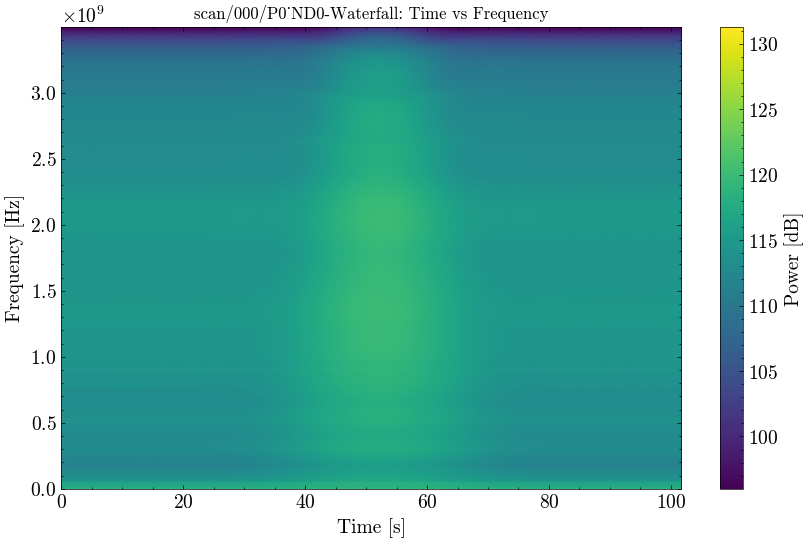

In [ ]:
# Plot waterfall: time vs frequency 
with h5py.File(filename, "r") as f:
    group = f["scan/000/P0_ND0"]   # select one scan

    freqs = group["frequency"][:]           # shape (65537,)
    times = group["timestamp"][:,0]         # shape (664,)
    spectra = group["spectrum"][:]          # shape (664, 65537)

# convert timestamp to relative seconds (optional)
times = times - times[0]

# plot waterfall
plt.figure(figsize=(10,6))
plt.imshow(10*np.log10(spectra.T+1e-12), 
           aspect="auto", 
           extent=[times[0], times[-1], freqs[0], freqs[-1]],
           origin="lower")
plt.colorbar(label="Power [dB]")
plt.xlabel("Time [s]")
plt.ylabel("Frequency [Hz]")  # or MHz depending on dataset units
plt.title("scan/000/P0_ND0-Waterfall: Time vs Frequency")
plt.show()

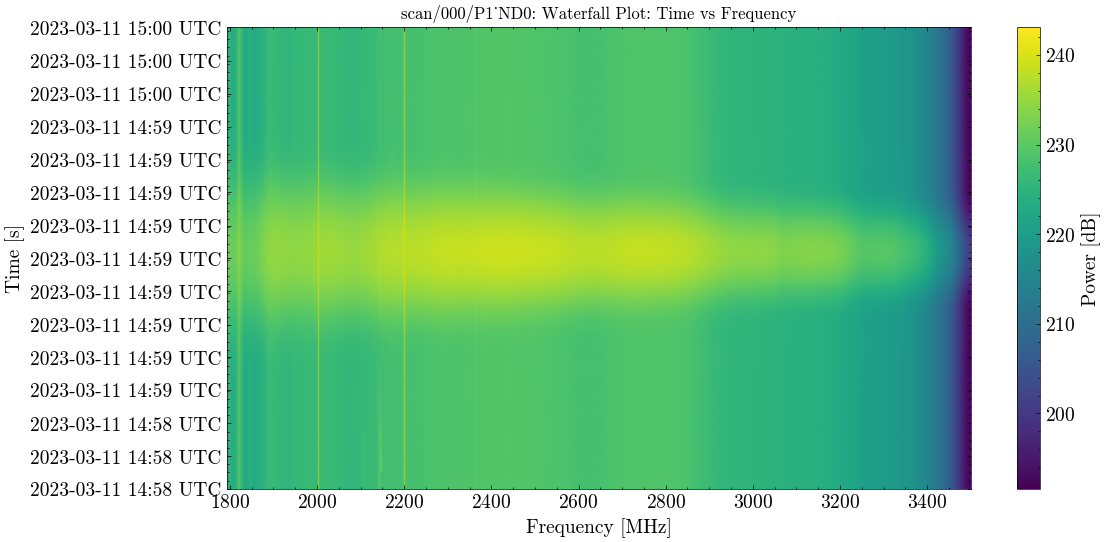

In [ ]:


with h5py.File(filename, "r") as f:
    for g in groups:
        #spectrum = f[f'{g}/spectrum'][:] # shape (666, 65537)
        spectrum = f[f"{g}/spectrum"][:,1600:-1]  # the 1600:-1 to 
        freq = f[f"{g}/frequency"][1600:-1] /1e6  # convert Hz -> MHz shape (65537,)
        time = f[f"{g}/timestamp"][:,0]  # shape  (666,)

        # convert spectrum to dB
        spectrum = 10*np.log10(spectrum**2 + 1e-12)

        # convert time to UTC datetime
        time_utc = pd.to_datetime(time, unit="s", utc=True)

        # create water fall plot
        plt.figure(figsize=(12,6))
        plt.imshow(
            spectrum,
            aspect='auto',
            extent=[freq.min(), freq.max(), 0, spectrum.shape[0]], # to have freq on x-axis and time on y-axis
            origin='lower',
            cmap='viridis'
        )

        plt.xlabel('Frequency [MHz]')
        plt.ylabel('Time [s]')
        plt.title(f'{g}: Waterfall Plot: Time vs Frequency')
        plt.colorbar(label='Power [dB]')

        # --- fixed tick handling ---
        n_ticks = 15
        tick_positions = np.linspace(0, len(time_utc)-1, n_ticks, dtype=int)
        tick_labels = [time_utc[i].strftime("%Y-%m-%d %H:%M UTC") for i in tick_positions]

        plt.yticks(tick_positions, tick_labels, rotation=0)


In [ ]:
# Search for the duraction of each outlier?
# Do we see the 2 GHz in all the scans?

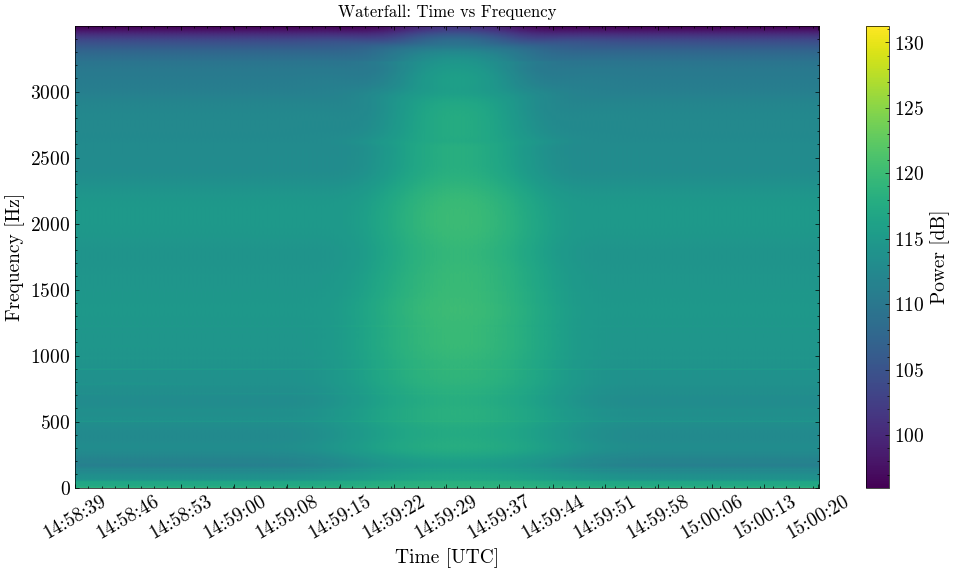

In [ ]:
with h5py.File(filename, "r") as f:
    group = f["scan/000/P0_ND0"]

    freqs = group["frequency"][:]/1e6          # (65537,)
    times = group["timestamp"][:,0]        # (664,)
    spectra = group["spectrum"][:]         # (664, 65537)

# convert timestamps to UTC datetime
time_utc = pd.to_datetime(times, unit="s", utc=True)

plt.figure(figsize=(12,6))
plt.imshow(10*np.log10(spectra.T+1e-12),
           aspect="auto",
           extent=[0, len(times), freqs[0], freqs[-1]],
           origin="lower")
plt.colorbar(label="Power [dB]")
plt.xlabel("Time [UTC]")
plt.ylabel("Frequency [Hz]")
plt.title("Waterfall: Time vs Frequency")

#--- fixed tick handling ---
n_ticks = 15
tick_positions = np.linspace(0, len(time_utc)-1, n_ticks, dtype=int)
tick_labels = [time_utc[i].strftime("%H:%M:%S") for i in tick_positions]

plt.xticks(tick_positions, tick_labels, rotation=30)

plt.show()

In [ ]:
times

array([1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854672e+09,
       1.67854672e+09, 1.67854672e+09, 1.67854672e+09, 1.67854673e+09,
       1.67854673e+09, 1.67854673e+09, 1.67854673e+09, 1.67854673e+09,
       1.67854673e+09, 1.67854673e+09, 1.67854673e+09, 1.67854673e+09,
       1.67854673e+09, 1.67854673e+09, 1.67854673e+09, 1.67854673e+09,
       1.67854673e+09, 1.67854673e+09, 1.67854673e+09, 1.67854673e+09,
      

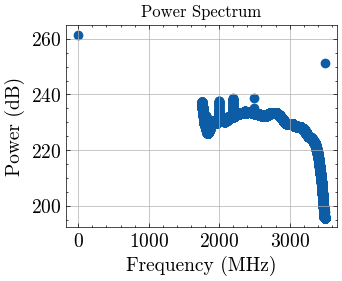

In [ ]:
plt.scatter(freqs, 10*np.log10(np.mean(np.abs(spectra)**2, axis=0)))
plt.xlabel("Frequency (MHz)")
plt.ylabel("Power (dB)")
plt.title("Power Spectrum")
plt.grid(True)
plt.show()

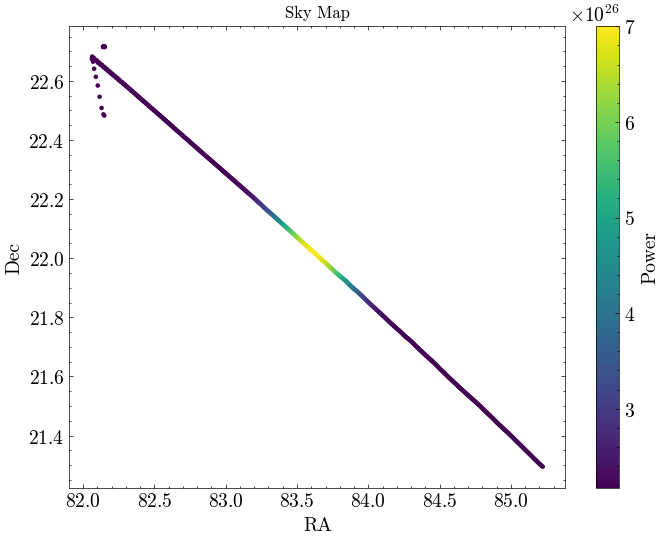

In [ ]:
# sky coverage
with h5py.File(filename, "r") as f:
    group = f["scan/000/P0_ND0"]

    ra = group['ra'][:]   
    dec = group['dec'][:]
    power = group['power'][:] 

plt.figure(figsize=(8, 6))
sc = plt.scatter(ra, dec, c=power, s=5, cmap='viridis')
plt.xlabel('RA')
plt.ylabel('Dec')
plt.title('Sky Map')
plt.colorbar(sc, label='Power')
plt.show()

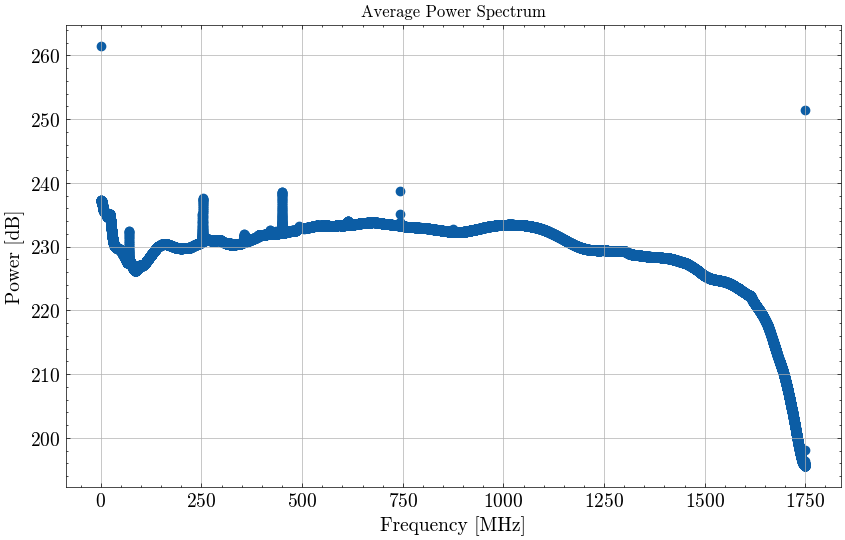

In [ ]:

with h5py.File(filename, "r") as f:
    # Example path to dataset (adjust if needed)
    spectra = f["scan/000/P0_ND0/spectrum"][:]   # shape (666, 65537)

# Average over time (axis=0) → single mean spectrum in dB
avg_spectrum = 10*np.log10(np.mean(spectra**2, axis=0))

# Get frequency axis in MHz
channel_width = 26702.880859375  # Hz (from your attributes)
n_channels = spectra.shape[1]

# Build frequency axis (starting at 0 for now)
freqs = np.arange(n_channels) * channel_width / 1e6  # in MHz

# Plot
plt.figure(figsize=(10,6))
plt.scatter(freqs, avg_spectrum)
plt.xlabel("Frequency [MHz]")
plt.ylabel("Power [dB]")
plt.title("Average Power Spectrum")
plt.grid(True)
plt.show()


For a waterfall plot (time vs. frequency channels, color = power spectrum), you should use the dataset:

000/P0_ND0/spectrum → shape (664, 65537)

664 = number of integrations (time steps)

65537 = number of frequency channels

You also have 000/P0_ND0/frequency (65537,), which lets you plot in MHz instead of just channel index.
And 000/P0_ND0/timestamp (664, 1) if you want real UTC time on the y-axis.

([<matplotlib.axis.YTick at 0x7f29bc15d220>,
 [Text(0, 0, '2023-03-11 14:58 UTC'),
  Text(0, 47, '2023-03-11 14:58 UTC'),
  Text(0, 94, '2023-03-11 14:58 UTC'),
  Text(0, 142, '2023-03-11 14:59 UTC'),
  Text(0, 189, '2023-03-11 14:59 UTC'),
  Text(0, 236, '2023-03-11 14:59 UTC'),
  Text(0, 284, '2023-03-11 14:59 UTC'),
  Text(0, 331, '2023-03-11 14:59 UTC'),
  Text(0, 378, '2023-03-11 14:59 UTC'),
  Text(0, 426, '2023-03-11 14:59 UTC'),
  Text(0, 473, '2023-03-11 14:59 UTC'),
  Text(0, 520, '2023-03-11 14:59 UTC'),
  Text(0, 568, '2023-03-11 15:00 UTC'),
  Text(0, 615, '2023-03-11 15:00 UTC'),
  Text(0, 663, '2023-03-11 15:00 UTC')])

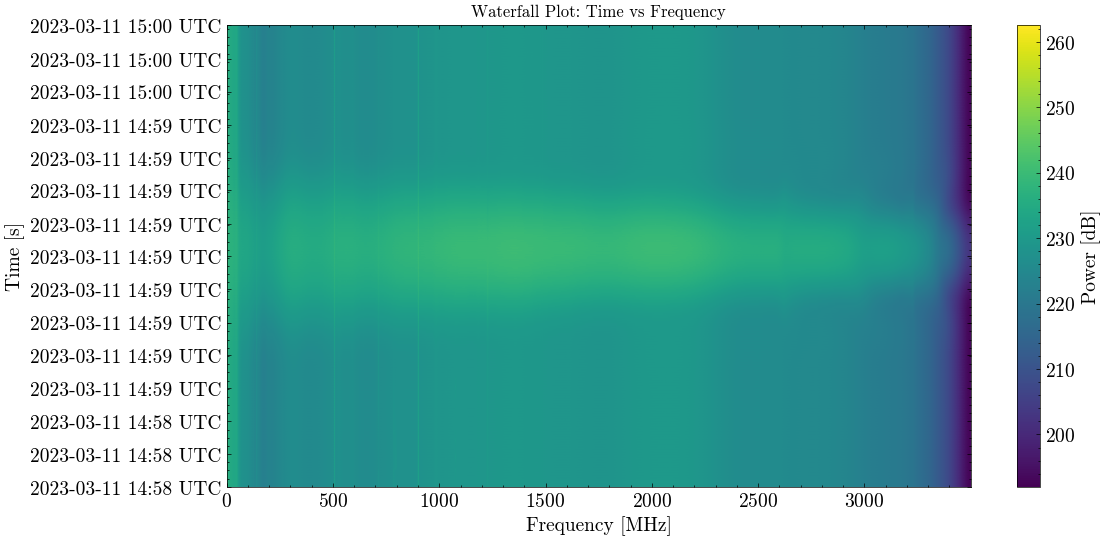

In [ ]:
# Plot water fall of time vs frequency channel

with h5py.File(filename, "r") as f:
    spectrum = f['scan/000/P0_ND0/spectrum'][:] # shape (666, 65537)
    freq = f['scan/000/P0_ND0/frequency'][:] /1e6  # convert Hz -> MHz shape (65537,)
    time = f['scan/000/P0_ND0/timestamp'][:,0]  # shape  (666,)

# convert spectrum to dB
spectrum = 10*np.log10(spectrum**2)

# convert time to UTC datetime
time_utc = pd.to_datetime(time, unit="s", utc=True)

# create water fall plot
plt.figure(figsize=(12,6))
plt.imshow(
    spectrum,
    aspect='auto',
    extent=[freq.min(), freq.max(), 0, spectrum.shape[0]], # to have freq on x-axis and time on y-axis
    origin='lower',
    cmap='viridis'
)

plt.xlabel('Frequency [MHz]')
plt.ylabel('Time [s]')
plt.title('Waterfall Plot: Time vs Frequency')
plt.colorbar(label='Power [dB]')

# --- fixed tick handling ---
n_ticks = 15
tick_positions = np.linspace(0, len(time_utc)-1, n_ticks, dtype=int)
tick_labels = [time_utc[i].strftime("%Y-%m-%d %H:%M UTC") for i in tick_positions]

plt.yticks(tick_positions, tick_labels, rotation=0)



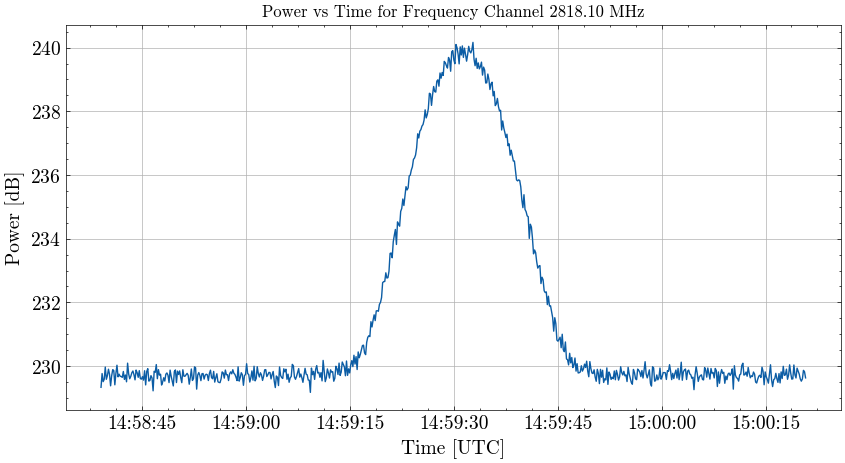

In [ ]:
# plot the power vs time for a given frequency channel
channel_idx = 40000  # example channel index
power_channel = spectrum[:, channel_idx] 
plt.figure(figsize=(10,5))
plt.plot(time_utc, power_channel)
plt.xlabel('Time [UTC]')
plt.ylabel('Power [dB]')
plt.title(f'Power vs Time for Frequency Channel {freq[channel_idx]:.2f} MHz')
plt.grid(True)
plt.show()

In [ ]:
power_channel.shape

(664,)

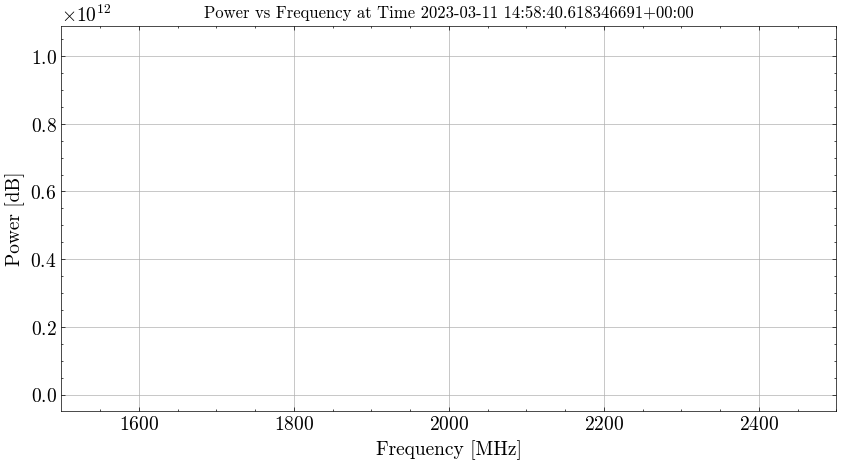

In [ ]:
# plot the power vs frequency for a given time index
time_idx = 10  # example time index
power_time = spectrum[time_idx, :]
plt.figure(figsize=(10,5))
plt.plot(freq, power_time)
plt.xlabel('Frequency [MHz]')
plt.xlim(1500,2500)
plt.ylabel('Power [dB]')
plt.title(f'Power vs Frequency at Time {time_utc[time_idx]}')
plt.grid(True)
plt.show()

In [ ]:
freq

array([1.79271126, 1.79273796, 1.79276466, ..., 3.49990654, 3.49993324,
       3.49995995])

--- Fit Results ---
Amplitude: 15.229 (True: 15.0)
Mean:      5.043 (True: 5.0)
Std Dev:   1.161 (True: 1.2)
Offset:    2.013 (True: 2.0)

--- Goodness of Fit ---
Root Mean Square Error (RMSE): 1.4566
Degrees of Freedom (ν):        96
Chi-Square (χ²):               94.3029
Reduced Chi-Square (χ²/ν):     0.9823


/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 956 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 963 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 967 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:238: RuntimeWarning: Glyph 957 missing from current font.
  font.set_text(s, 0.0, flags=flags)
/home/chavango/anaconda3/envs/SKAMPIDATA/lib/python3.9/site-packages/matplotlib/backends/backend_agg.py:201: RuntimeWarning: Glyph 956 missing from current font.
  font.set_text(s, 0, flags=flags)
/home/c

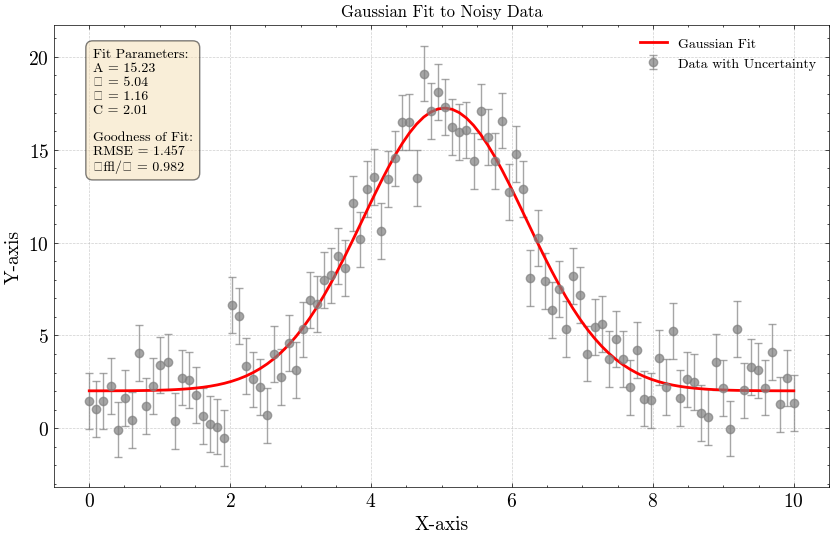

In [ ]:

from scipy.optimize import curve_fit

# --- 1. Define the Model Function ---
# This is the function we want to fit to our data.
def gaussian_model(x, amplitude, mean, stddev, offset):
    """A Gaussian function with a vertical offset."""
    return amplitude * np.exp(-((x - mean) ** 2) / (2 * stddev ** 2)) + offset

# --- 2. Generate Sample Data ---
# In a real-world scenario, you would load your data here.
# For this example, we'll create synthetic data: a Gaussian with some noise.

# True parameters for our synthetic data
true_amplitude = 15.0
true_mean = 5.0
true_stddev = 1.2
true_offset = 2.0
data_points = 100

# Generate x values
x_data = np.linspace(0, 10, data_points)

# Generate y values with noise. The noise level is our "uncertainty".
# np.random.normal generates noise from a normal distribution.
# The `scale` parameter is the standard deviation of the noise.
y_uncertainty = np.full_like(x_data, 1.5) # Assume a constant uncertainty of 1.5 for all points
y_data = (
    gaussian_model(x_data, true_amplitude, true_mean, true_stddev, true_offset) +
    np.random.normal(loc=0, scale=y_uncertainty)
)


# --- 3. Perform the Fit ---
# `curve_fit` needs the model function, x-data, and y-data.
# `p0` is an initial guess for the parameters, which can help the algorithm converge.
initial_guess = [10.0, 4.5, 1.0, 1.0]

# `sigma` is the crucial parameter for a proper chi-square calculation later.
# It tells curve_fit the uncertainty of each y_data point.
# `absolute_sigma=True` ensures the returned covariance matrix is correctly scaled.
popt, pcov = curve_fit(
    f=gaussian_model,
    xdata=x_data,
    ydata=y_data,
    p0=initial_guess,
    sigma=y_uncertainty,
    absolute_sigma=True
)

# The fitted parameters are in `popt`
fit_amplitude, fit_mean, fit_stddev, fit_offset = popt
y_fit = gaussian_model(x_data, *popt)


# --- 4. Calculate Goodness of Fit ---

# Calculate RMSE
residuals = y_data - y_fit
rmse = np.sqrt(np.mean(residuals**2))

# Calculate Chi-Square and Reduced Chi-Square
# The number of degrees of freedom (nu)
dof = len(x_data) - len(popt)

# The formal chi-square calculation
chi_square = np.sum((residuals / y_uncertainty) ** 2)
reduced_chi_square = chi_square / dof


# --- 5. Report and Visualize Results ---

print("--- Fit Results ---")
print(f"Amplitude: {fit_amplitude:.3f} (True: {true_amplitude})")
print(f"Mean:      {fit_mean:.3f} (True: {true_mean})")
print(f"Std Dev:   {fit_stddev:.3f} (True: {true_stddev})")
print(f"Offset:    {fit_offset:.3f} (True: {true_offset})")
print("\n--- Goodness of Fit ---")
print(f"Root Mean Square Error (RMSE): {rmse:.4f}")
print(f"Degrees of Freedom (ν):        {dof}")
print(f"Chi-Square (χ²):               {chi_square:.4f}")
print(f"Reduced Chi-Square (χ²/ν):     {reduced_chi_square:.4f}")

# Plot the results
plt.figure(figsize=(10, 6))
# Plot the original data with error bars
plt.errorbar(x_data, y_data, yerr=y_uncertainty, fmt='o', label='Data with Uncertainty', capsize=3, color='gray', alpha=0.7)
# Plot the fitted Gaussian
plt.plot(x_data, y_fit, 'r-', label='Gaussian Fit', linewidth=2)
plt.title("Gaussian Fit to Noisy Data")
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)

# Add fit results to the plot
fit_text = (
    f"Fit Parameters:\n"
    f"A = {fit_amplitude:.2f}\n"
    f"μ = {fit_mean:.2f}\n"
    f"σ = {fit_stddev:.2f}\n"
    f"C = {fit_offset:.2f}\n\n"
    f"Goodness of Fit:\n"
    f"RMSE = {rmse:.3f}\n"
    f"χ²/ν = {reduced_chi_square:.3f}"
)
plt.text(0.05, 0.95, fit_text, transform=plt.gca().transAxes, fontsize=10,
         verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', fc='wheat', alpha=0.5))

plt.show()


